## 1.핵심 원리: 반복 정제

VAE나 GAN(Generative Adversial Network)과 같은 이전 기술들은 모델의 단일 순전파 과정을 거쳐 최종 출력물을 생성한다. 이는 모델이 첫 시도에서 모든 것을 올바르게 해야함을 의미한다. 실수가 발생하면 이를 되돌려 수정할 수 없다. 반면 확산 모델은 여러 단계에 걸쳐 반복하며 출력물을 생성한다. 이러한 반복 정제(iterative refinement)과정에서 이전 단계의 오류를 수정하고 점진적으로 출력물을 계선할 수 있다. 

Hugging face의 diffuser library를 사용해 사전 학습된 확산 모델을 불러올 수 있다. 이 라이브러리는 이미지를 직접 생성하는데 사용할 수 있는 고수준 라이브러리를 제공한다. 여기서는 초기게 공개된 확산 모델인 'ddpm-celebahq-256' model을 로드할 것이다. 이 모델은 고품질 연예인 이미지 데이토셋은 CelevA-HQ로 학습되었으므로 해당 데이터셋과 유사한 이미지를 생성한다. 이 모델을 사용하여 노이즈에서 이미지를 생성해 볼 수 있다. 

In [1]:
%pip install diffusers genaibook.core
!pip -q install genaibook

ERROR: Could not find a version that satisfies the requirement genaibook.core (from versions: none)
ERROR: No matching distribution found for genaibook.core
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.7/60.7 MB 19.0 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 129.0 MB/s eta 0:00:0000:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 290.4/290.4 kB 31.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 10.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 128.5 MB/s eta 0:00:0000:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.8/135.8 kB 16.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 48.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 116.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 107.4 MB/s eta 0:00:0000:01


Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


model_index.json:   0%|          | 0.00/180 [00:00<?, ?B/s]

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

scheduler_config.json:   0%|          | 0.00/256 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/790 [00:00<?, ?B/s]

diffusion_pytorch_model.bin:   0%|          | 0.00/455M [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/2 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--google--ddpm-celebahq-256/snapshots/cd5c944777ea2668051904ead6cc120739b86c4d: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--google--ddpm-celebahq-256/snapshots/cd5c944777ea2668051904ead6cc120739b86c4d.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


  0%|          | 0/1000 [00:00<?, ?it/s]

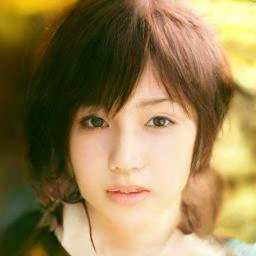

In [2]:
import torch
from diffusers import DDPMPipeline
from genaibook.core import get_device
device = get_device()
image_pipe = DDPMPipeline.from_pretrained("google/ddpm-celebahq-256")
image_pipe.to(device)

image_pipe().images[0]

- 코드를 실행하면 생성에 1000단계(DDPMPipeline의 기본 num_inference_steps의 값이 1000)가 소요됨을 알 수 있다. 이 확산 파이프라인은 최종 이미지를 얻는데 10000번의 정제단계 및 순전파를 거쳐야 한다. 이는 기본 확산 모델의 주요 단점이며, 고품질 이미지를 생성하는데 많은 단계가 필요해 GAN보다 추론 시간이 느리다. 

이 샘플링 과정을 단계벼롤 재현하여 내부에서 어떤 무슨 일이 일어나는지 더 잘 이해해보자. 먼저 확산 과정을 시작할 때 샘플 \mathbf{x}를 4개의 무작위 배치로 초기화한다. 즉, 일부 무작위 노이즈를 샘플링한다. 입력 이미지를 점진적으로 denoising하고 최종적으로 실제 분포에서 샘플을 얻기 위해 30단계를 실행할 것이다. 

이미지를 생성해보자. 다음 이미지의 왼쪽에는 주어진 단계의 입력(무작위 노이즈로 시작)이 있고, 오른쪽에는 모델이 예측한 최종이미지가 있다. 첫 번째 행의 결과는 별로 좋지 않다. 주어진 확산 단계에서 최종 예측 이미ㅣㅈ를 바로 생성하는 대신, 입력 \mathbf{x}를 모델에 다시 입력하여 다음 단계를 진행한다. 그러면 약간 개선된 예측이 나와서 \mathbf{x}를 조금 더 업데이트 하는 방법을 계속 진행한다. 그러면 약간 개선된 예측이 나와서 \mathbf{x}를 조금 더 업데이트하는 방법을 계속 진행한다. 충분한 단계를 거치면 모델은 고품직의 현실적인 이미지를 생성할 수 있다. 

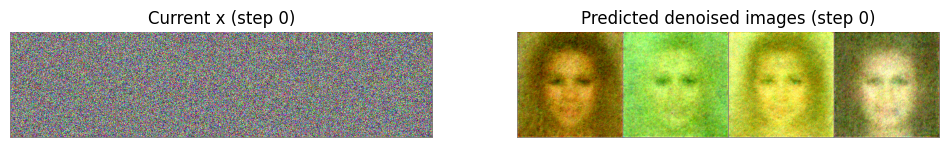

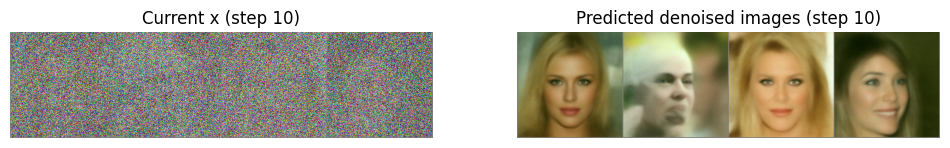

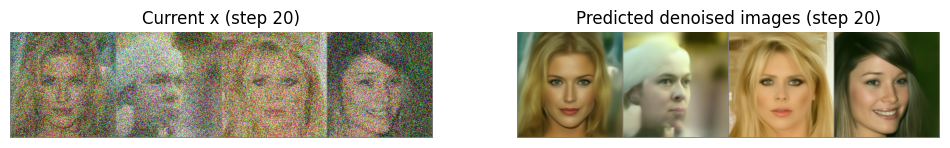

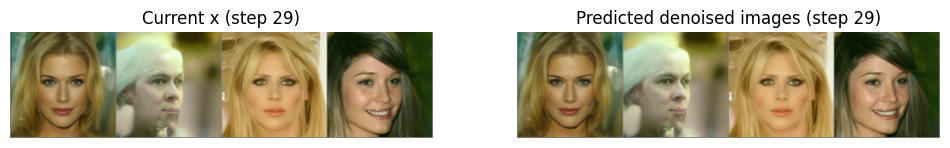

In [3]:
from genaibook.core import plot_noise_and_denoise


# 무작위 시작점은 4개의 이미지 배치
# 각 이미지는 3채널,256x256 크기의 이미지
image = torch.randn(4, 3, 256, 256).to(device)

# 특정 확산 단계 수 설정
image_pipe.scheduler.set_timesteps(num_inference_steps=30)


# 샘플링 타임스텝을 통해 반복
for i, t in enumerate(image_pipe.scheduler.timesteps):
    
    # 현재 샘플 x와 타임스텝 t가 주어졌을 때 예측 얻기
    # 추론을 하기에 gradient를 계산할 필요가 없으며 torch.inference_mode를 사용
    with torch.inference_mode():

        # 모델이 현재의 타입스텝을 알 수 있도록 t를 전달한다. 
        noise_pred = image_pipe.unet(image, t)["sample"]
    
    # 스케쥴러로 업데이트된 x를 나타냄
    scheduler_output = image_pipe.scheduler.step(noise_pred, t, image)

    # x 업데이트
    image = scheduler_output.prev_sample

    if i % 10 == 0 or i == len(image_pipe.scheduler.timesteps) - 1:
        plot_noise_and_denoise(scheduler_output, i)

## 2. 확산 모델 학습

확산 모델을 학습시키려면 다음 과정을 반복 수행하게 된다. 
1. 학습 데이터에서 일부 이미지를 로드한다. 
2. 다양한 양의 노이즈를 추가한다. 극도로 노이즈가 많은 이미지와 거의 완벽한 이미지 모두를 모델이 수정(denoisng)하기 원하기에 다양한 양의 노이즈가 포함된 데이셋이 필요하다.
3. 노이즈가 추가된 입력 버전을 모델에 제공한다.
4. 이 모델이 입력 데이터를 얼마나 잘 denosing하는지 평가한다. 
5. 이 정보를 사용하여 모델 가중치를 업데이트 한다. 

학습된 모델로 새 이미지를 생성하려면 처음에는 완전히 무작위로 입력을 시작하고 모델에 반복해서 입력을 전달한다. 각 반복에서 모델의 예측에 따라 입력을 조금씩 업데이트 한다. 여러 샘플링 방법은 이 과정을 단순화하여 가능한 적은 단계로 좋은 이미지를 생성하도록 프로세스를 단순화한다. 

### 2.1 데이터

이 예제에서는 hugging face 허브에서 제공하는 이미지 데이터셋 중에서 1000개의 나비 사진 컬렉션을 사용할 것이다. 

In [4]:
!pip -q install datasets
from datasets import load_dataset

dataset = load_dataset("huggan/smithsonian_butterflies_subset", split="train")

README.md:   0%|          | 0.00/609 [00:00<?, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


dataset_infos.json: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/237M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/1000 [00:00<?, ? examples/s]

모델을 학습시키기 전에 데이터를 준비해야한다. 이미지는 일반적으로 픽셀의 격자로 표현된다. 다음을 수행해 이미지를 학습 가능한 형태로 준비한다. 
1. 크기를 고정된 크기로 조정한다. 모델이 모든 이미지 차원이 동일할 것으로 예상하므로 이는 필수 작업이다. 
2. 수평으로 무작위 뒤집기를 해서 데이터 증강을 추가하면 모델이 더 강력해지고 더 많은 데이터로 학습할 수 있다. 이는 모델이 보지 않은 데이터에 더 잘 일반화하도록 돕는다. 
3. 파이토치 텐서로 변환해 색상값을 0과 1사이의 실수로 표현한다. 모델 입력은 항상 다차원 행렬이나 텐서로 형식화해야 한다. 
4. 평균이 0이고 값이 -1과 1 사이가 되도록 정규화한다. 이는 딥러닝 모델 학습에서 일반적으로 사용하는 방법으로, 모델이 더 빠루고 효과적으로 학습하돋록 돕는다. 
이런 변환은 'torchvision.transforms'를 사용해 정의할 수 있다. 

In [5]:
from torchvision import transforms

image_size = 64

# 변환정의
preprocess = transforms.Compose(
    [
        transforms.Resize((image_size, image_size)),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.5], [0.5])
    ]
)

- dataset 라이브러리이 set_transform()를 활용하면 데이터가 사용될 때 즉시 변환을 적용할 수 있다. 

마지막으로 데이터셋을 'DataLoader'로 감싸면 데이터 배치 반복을 쉽게 할 수 있어 학습 코드가 간결해진다. 

In [6]:
def transform(examples):
    examples = [preprocess(image) for image in examples["image"]]
    return {"images": examples}

dataset.set_transform(transform)
batch_size = 16

train_dataloader = torch.utils.data.DataLoader(
    dataset, batch_size=batch_size, shuffle=True
)

배치를 로드하고 이미지를 살펴보며 작업이 잘 되었는지 확인해보자. 

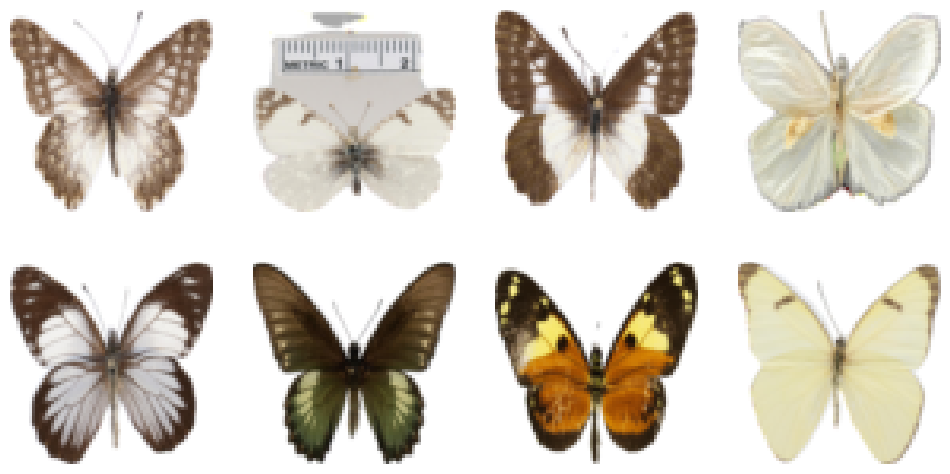

In [7]:
from genaibook.core import show_images
batch = next(iter(train_dataloader))

show_images(batch["images"][:8]*0.5 + 0.5)

### 4.2 노이즈 추가하기

데이터를 단계적으로 손상시키기 위한 방법으로는 이미지에 노이즈를 추가하는 방식을 사용한다. 입력에 얼마나 많은 노이즈가 있든 디노이징하는 견고한 모델을 학습시키는 것이 목표이므로 학습 데이터에 다영한 양의 노이즈를 추가할 것이다. 추가하는 노이즈의 양은 노이즈 스케줄러로 제어하며, 이는 확산 모델의 핵심 요소이다. 

지금은 DDPM 논문을 기반으로 한 일반적인 접근 방식을 살펴보자. 디퓨저에서 노이즈 추가하는 'Scheduler'라는 클래스에서 처리하는데, 이는 이미지 배치와 타입스텝 목록을 입력받아 해당 이미지에 노이즈가 추가된 버전을 어떻게 만들지 결정한다. 다음 코드는 입력 ㅇ미지 가각에 점점 더 많은 양의 노이즈를 적용한다. 

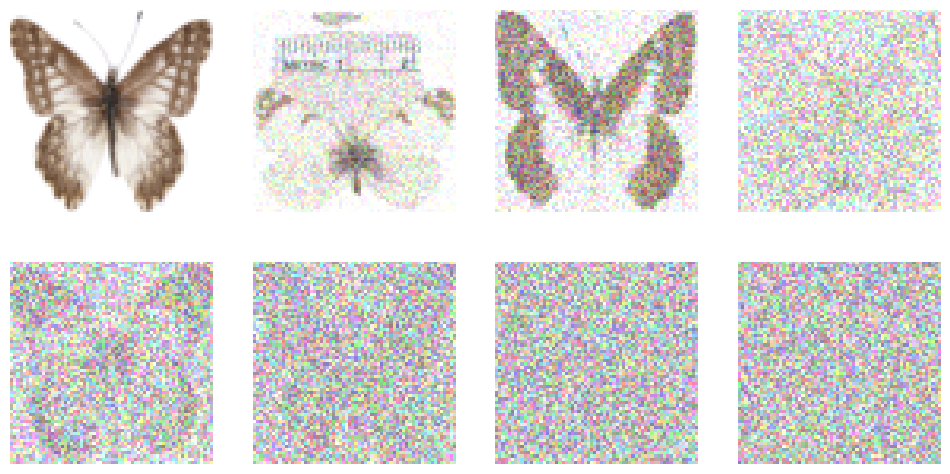

In [8]:
from diffusers import DDPMScheduler

scheduler = DDPMScheduler(
    num_train_timesteps=1000, beta_start=0.001, beta_end=0.02
)
timesteps = torch.linspace(0, 999, 8).long()

# 데이터셋에서 8개의 이미지를 로드하고 점점 더 많은 양의 노이즈를 추가한다. 
x = batch["images"][:8]
noise = torch.rand_like(x)
noised_x = scheduler.add_noise(x, noise, timesteps)
show_images((noised_x*0.5 + 0.5).clip(0, 1))

### 2.3 U-Net

U-Net은 이미지 분할과 같은 작업을 위해 개발된 CNN이다. U-Net은 입력과 출력이 동일한 형태라는 특징이 있다. U-Net은 입력의 공간적 크기를 줄이는 여러 개의 downsamopling 층에 이어서 입력의 공간적 범위를 다시 증가시키는 일련의 upsampling층으로 구성된다. downsampling은 일반적으로 skip connection으로 이어지는데 이는 downsampling층의 출력을 upsampling 층의 입력에 연결한다. 이를 통해 upsasmpling 층은 초기 층의 미세산 세부 사항을 통합할 수 있어 디노이징 과정에서 중요한 고해상도 정보를 보존할 수 있다. 

Diffuser 라이브러리에서 사용하는 U-Net 아키텍쳐는 2015년에 제안된 원래의 U-Net 보다 attention, residual block과 같은 기능이 추가되었다. 핵심 아이디어는 입력을 받아 같은 형태의 예측을 생성할 수 있다는 점이다. 확산 모델에서는 입력이 노이즈가 있는 이미지이고 출력은 예측된 노이즈일 수 있다. 이 정보를 바탕으로 입력 이미지를 디노이징할 수 있다. 

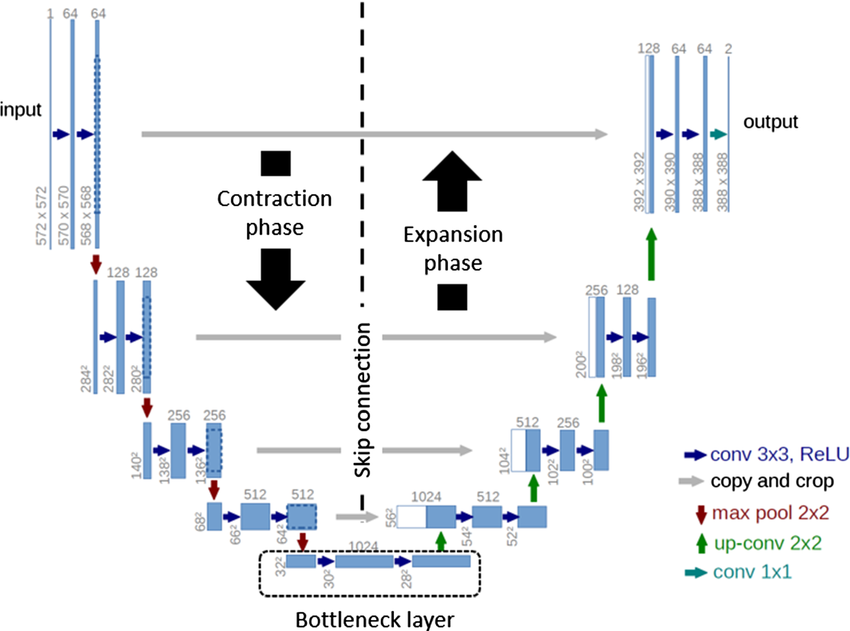

U-Net을 만들고 그 안에 이미지 배치를 넣는 방법을 알아보자. 

In [9]:
from diffusers import UNet2DModel

model = UNet2DModel(
    in_channels=3,
    sample_size=64,

    block_out_channels=(64, 128, 256, 512),
    down_block_types=(
        "DownBlock2D",
        "DownBlock2D",
        "AttnDownBlock2D",
        "AttnDownBlock2D",
    ),
    up_block_types=("AttnUpBlock2D", "AttnUpBlock2D", "UpBlock2D", "UpBlock2D"), 
).to(device)

with torch.inference_mode():
    out = model(noised_x.to(device), timestep=timesteps.to(device)).sample

print(noised_x.shape)
print(out.shape)

torch.Size([8, 3, 64, 64])
torch.Size([8, 3, 64, 64])


### 2.4 학습

데이터와 모델이 준비되었으니 학습을 시작하자. 각 학습 단계에서 다음을 수행한다. 
1. 이미지를 여러장 불러온다. 
2. 이미지에 노이즈를 추가한다. 추가되는 노이지의 양은 지정된 타임스텝 수에 따라 달라진다. 타임스텝이 많을수록 노이즈도 많다. 앞서 설명했듯이 모델이 노이즈가 적은 이미지와 노이즈가 많은 이미지 모두에서 디노이징 하기를 원한다. 이를 위해 무작위 양의 노이즈를 추가할 것이므로 무작위 타임스텝 수를 선택한다. 
3. 노이즈가 추가된 이미지를 모델에 입력한다. 
4. MSE를 사용해서 손실을 계산한다. MSE는 U-Net 모델의 노이즈 예측과 같은 regression작업에서 일반적으로 사용하는 손실함수이다. 예측값과 실제값 사이의 평균 제곱 오차는 예측된 노이즈와 실제 노이즈 사이에서 계산되며, 손실을 최소화하여 모델이 더 현실적인 이미지를 생성하도록 돕는다. 이를 노이즈 목적함수, 또는 epsilon 목적함수라고 한다.
5. 손실을 역전파하여 optimizer로 모델 가중치를 업데이트한다. 

In [10]:
from torch.nn import functional as F

num_epochs = 100
lr = 1e-4
optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
losses = []

for epoch in range(num_epochs):
    for batch in train_dataloader:

        # 입력 이미지 로드
        clean_images = batch["images"].to(device)
        
        # 이미지에 추가할 노이즈 샘플링
        noise = torch.randn(clean_images.shape).to(device)

        # 각 이미지에 대한 무작위 타임스텝 샘플링
        timesteps = torch.randint(
            0, 
            scheduler.config.num_train_timesteps,
            (clean_images.shape[0],),
            device=device,
        ).long()

        # 각 타임스텝의 노이즈 크기에 따라 깨끘한 이미지에 노이즈 추가
        noisy_images = scheduler.add_noise(clean_images, noise, timesteps)

        # 노이즈에 대한 모델 예측 획득, 모델 추가 조건부로 타입스텝도 입력으로 사용
        noise_pred = model(noisy_images, timesteps, return_dict = False)[0]

        # 예측과 실제 노이즈 비교
        loss = F.mse_loss(noise_pred, noise)

        # 시각화를 위해 loss function 저장
        losses.append(loss.item())

        # 이 손실에 기반하여 옵티마이저로 모델 매개변수 업데이트
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()


Text(0.5, 0, 'Training step')

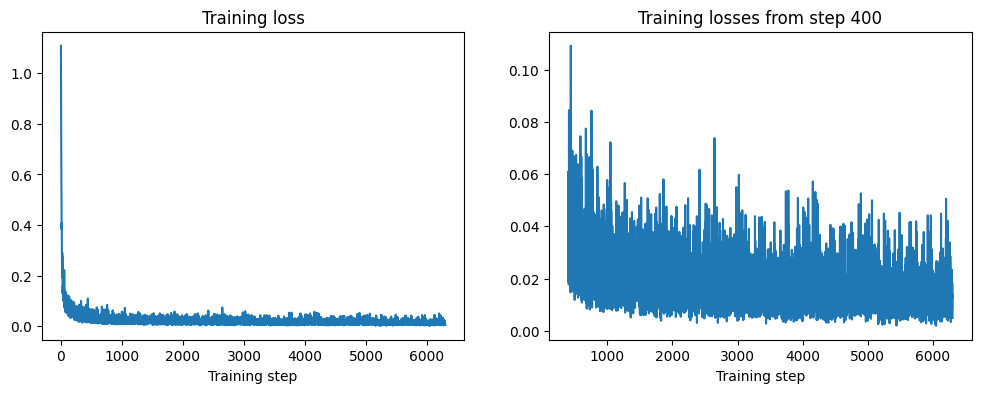

In [11]:
from matplotlib import pyplot as plt

plt.subplots(1, 2, figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(losses)
plt.title("Training loss")
plt.xlabel("Training step")

plt.subplot(1, 2, 2)
plt.plot(range(400, len(losses)), losses[400:])
plt.title("Training losses from step 400")
plt.xlabel("Training step")

- 모델이 디노이징을 학습함에 따라 손실 곡선은 하락 추세를 보인다,. 하지만 곡선이 다소 불안정한데, 이는 반복마다 다른 수의 노이즈 ㅏㅌ임스텝을 사용하기 때문이다. 노이즈 예측의 MSE를 보고 모델이 샘플 생성을 얼마나 잘할지 판단하기는 어렵다. 

### 2.5 샘플링

모델이 준비되었으니 추론을 수행하고 이미지를 생성해보자. Diffuser 라이브러리는 파이프 라인이라는 개념을 사용해 확산 모델로 샘플을 생성하는데 필요한 모든 구성 요소를 번들로 제공한다. 파이프라인을 사용해 앞에서 학습한 U-Net을 테스트할 수 있다. 다음은 몇 가지 예시이다. 학습한 모델은 64, 64 사이즈이기 때문에 아래의 결과를 이를 확대한 것이므로 다소 깨진다. 

  0%|          | 0/1000 [00:00<?, ?it/s]

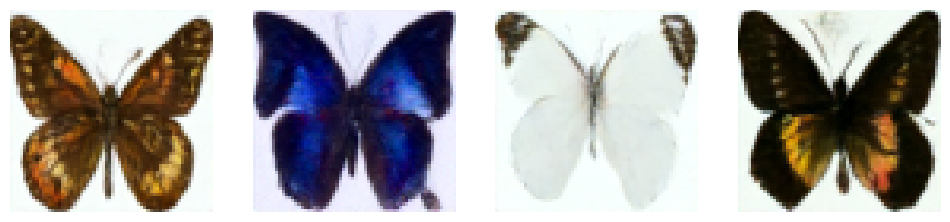

In [12]:
pipeline = DDPMPipeline(unet=model, scheduler=scheduler)
ims = pipeline(batch_size=4).images
show_images(ims, nrows=1)

샘플을 만드는 작업을 파이프라인에[ 맡기면 내부에서 무슨 일이 일어나는지 알 수 없으므로 파이프라인의 'call()' 메서드에 있는 코드를 기반으로 모델이 입력 이미지를 점진적으로 개선하는 과정을보여주는 간단한 샘플링 루프를 만들어 볼 수 있다. 

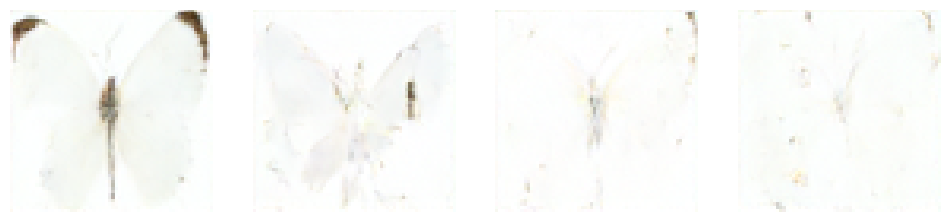

In [13]:
sample = torch.rand(4, 3, 64, 64).to(device)

for t in scheduler.timesteps:
    
    # 모델 예측 획득
    with torch.inference_mode():
        noise_pred = model(sample, t)["sample"]

    # 단계적으로 샘플 업데이트
    sample = scheduler.step(noise_pred, t, sample).prev_sample

show_images(sample.clip(-1, 1)*0.5 + 0.5, nrows=1)

- 이는 반복 정제 개념을 사용한 코드와 동일하지만, 내부 동작을 더 잘 이해할 수 있다. 디퓨저 라이브러리의 DDPMPipeline구현을 보면 로직이 앞서 구현한 코드와 매우 유사함을 알 수 있다. 
- 완전한 무작위 입력으로 시작해 모델이 여러 단계에 걸쳐 이를 정제한다. 각 단계에서는 해당 타임스텝에서 모델의 노이즈 예측을 기반으로 입력을 조금씩 업데이트 한다. pipeline.scheduler.step() 호출 뒤에 숨겨진 복잡성은 아직 추상화되어 있다. 

### 2.6 평가

생성 모델을 평가하는 일은 매우 복잡하며 본질적으로 주관적인 작업이다. 예를 들어 "image of a cat with sunglasses"라는 입력 프롬프트의 올바른 결과물이 될 수 있는 이미지는 무수히 많다. 일반적으로 사람이 직접 결과물을 비교하는 정성적 평가와 수치화된 정량적 지표를 함께 활용한다. 이러한 지표는 평가의 틀을 제공하지만 높은 이미지 품질을 보장하지는 않는다. 

Fréchet Inception Distance(FID) 점수는 생성 모델의 성능을 평가하는데 널리 사용하는 방법이다. 이 점수는 두 이미지 데이터셋 간의 유사도를 비교한다. 사전 학습된 신경망을 활용해 두 데이터셋에서 추출한 특성 맵 간의 통계를 비교함으로써 생성된 샘플이 실제 샘플과 얼마나 가까운지 측정한다. 

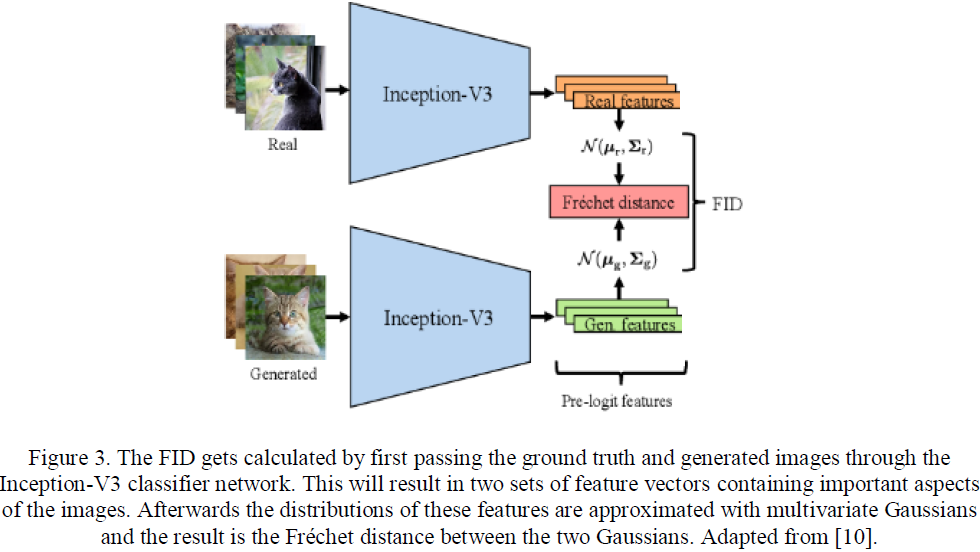



  
점수가 낮을수록 해당 모델이 생성한 이미지의 품질과 현실감이 더 뛰어나다고 볼 수 있다. FID가 인기 있는 이유는 인간의 주관적 판단에 의존하지 않으면서도 다양한 생성 신경망에 대한 '객관적인'비교 기준을 제공하기 때문이다. 

FID가 편리하긴 하지만 알아두어여 할 중요한 주의 사항이 있다. 
- FID는 두 분포를 비교하도록 설계되었다. 따라서 비교할 수 있는 기준 데이터셋에 접근할 수 있어야 한다. 또한 단일 생성물(e.g. image)로는 FID를 계산할 수 없다. 
- FID는 계산에 사용된 샘플 수에 따라 달라지므로 두 모델의 점수를 비교할 때는 동일한 수의 샘플을 사용하여 계산된 점수인지를 확인해야 한다, 일반적으로 50_000 개의 샘플을 사용하지만, 개발중에는 시간 절약을 위해 적은 수의 샘플로 평가하고 결과를 발표할 준ㄴ비가 된 후에만 완전한 평가를 수행할 떄도 많다. 
- FID는 많은 요소에 민감할 수 있다. 예를 들어 다른 수의 추론 단계는 매우 다른 FID로 이어질 것이다. 스케쥴러(e.g. DDPM)도 FID에 영향을 미친다. 
- FID를 계산할 때에는 이미지 크기가 299 x 299로 조정된다. 따라서 해상도가 극도로 낮거나 높은 이미지에 대한 지표로서는 적합하지 않을 수 잇다. 또한 딥러닝 프레임워크 간에 크기를 조정하는 방식에 차이가 있어, FID에 약간 차이가 발생할 수도 있다. 
- FID에 사용되는 특성 추출기 신경망은 일반적으로 이미지넷 분류 작업에서 학습된 모델이다. 다른 도메인에서 이미지를 생성할 떄는 이 모델이 학습한 특징이 덜 유용할 수 있다. 더 정확한 접근 방식은 도메인별 데이터로 분류 신경망을 먼저 학습시키는 것이지만, 이는 다른 논문이나 기술 간의 점수 비교를 더 어렵게 만든다. 현재로써는 이미지넷 모델이 표준 선택이다. 
- 나중에 평가하기 위해 생성된 샘플을 저장할 때, 포맷과 압축이 FID 거리 점수에 영향을 미칠 수 있다. 가능하면 저품질 JPEG 이미지는 피하는 것이 좋다. 

이러한 주의사항을 모두 고려하더라도, FID 점수는 품질의 대략적인 측정일 뿐이며 이미지가 더 실제처럼 보이게 하는 미묘한 뉘앙스를 완벽하게 포착하지는 못한다. 생성 모델의 평가는 호라발한 연구분야다 Kernel Inception Distance(KID)와 Inception 점수 같은 표준 지표에도 FID와 유사한 문제가 잇다. 따라서 이러한 평가방식을 바탕으로 모델 간의 성능을 대략 비교하되, 각 모델이 생성한 실제 이미지도 함께 살펴보아야 더 정확하게 평가할 수 있다. 

FID 거리나 KID로 측정하는 이미지 품질은 텍스트-이미지 모델의 성능을 평가하는데 사용하는 기준 중 하나다. 텍스트-이미지 모델의 종합 평가(Holistic Evaluation of Text-to-Image Model, HEIM)와 같은 기준은 프롬프트 준수, 독창성, 추론 능력, 다국어성, 편향성과 유해성 부재 등과 같이 텍스트-이미지 모델이 가져야 할 바람직한 특성을 함께 고려한다. 

인간의 선호도는 상당히 주관적인 분야에서도 품질 평가의 가장 신뢰할 수 있는 기준으로 남아있다. 예를 들어 Parti 프롬프트 데이터셋은 동일한 텍스트 지시문으로 여러 모델이 생성한 이미지를 사람들이 직접 평가함으로써, 어떤 모델이 더 좋은 품질의 이미지를 생성하는지 객간적으로 비교하게 해준다. 이 데이터셋은 다양한 난이도와 카테고리에 걸친 1600개의 프롬프트를 포함하며, 5장에서 살펴볼 텍스트-이미지 모델들을 비교 평가하는 도구로 활용된다. 

## 3. 노이즈 스케줄 심층 분석

앞서 살펴본 학습 과정에는 다양한 양의 노이즈를 추가하는 단계가 있었다. 0부터 1000 사이에서 무작위로 타임스텝을 선택한 다음, 스케줄러가 알아서 적절한 양의 노이즈를 더하도록 했다. 마찬가지로 추론 과정에서도 스케줄러에 의존해 어떤 타임스텝을 사용할지, 모델의 예측값을 바탕으로 한 단계에서 다음 단계로 어떻게 진행할지 결정한다. 노이즈를 얼마나 추가할지 정하는 것은 모델의 성능에 극적인 영향을 미치는 매우 중요한 설계이다. 이번 절에서는 이것이 중요한 이유와 실제로 사용되는 여러 접근 방식을 자세히 알아볼 것이다. 

### 3.1 노이즈를 추가하는 이유

확산 모델의 핵심 원리는 반복 정제 과정이다. 학습 단계에서는 입력 데이터에 다양한 수준의 손상을 가하고, 추론 단계에서는 완전히 손상된 입력(순수히 노이즈 이미지)에서 시작해 점진적으로 복원해 나가면서 최종적으로 좋은 결과물을 얻는 것을 목표로 한다. 

지금까지 가우시안 노이즈 추가(adding gaussian noise)라는 특정 손상 방식을 주로 사용했다. 이 방식에 중점을 둔 주된 이유는 확산 모델의 이론적 기반이 가우시안 노이즈 사용을 전제로 하기 때문이다. 다른 손상 방법을 사용한다면 엄밀히 말해 확산을 수행하는 것이 아니게 된다. 

그러나 cold diffusion 논문(https://arxiv.org/pdf/2208.09392)은 이론적 편리함을 위해 이 방법을 사용할 필요가 없음을 증명했다. 저자들은 확산 모델과 같은 접근 방식이 여러 손상 방법에서 작동함을 보여주었다. 

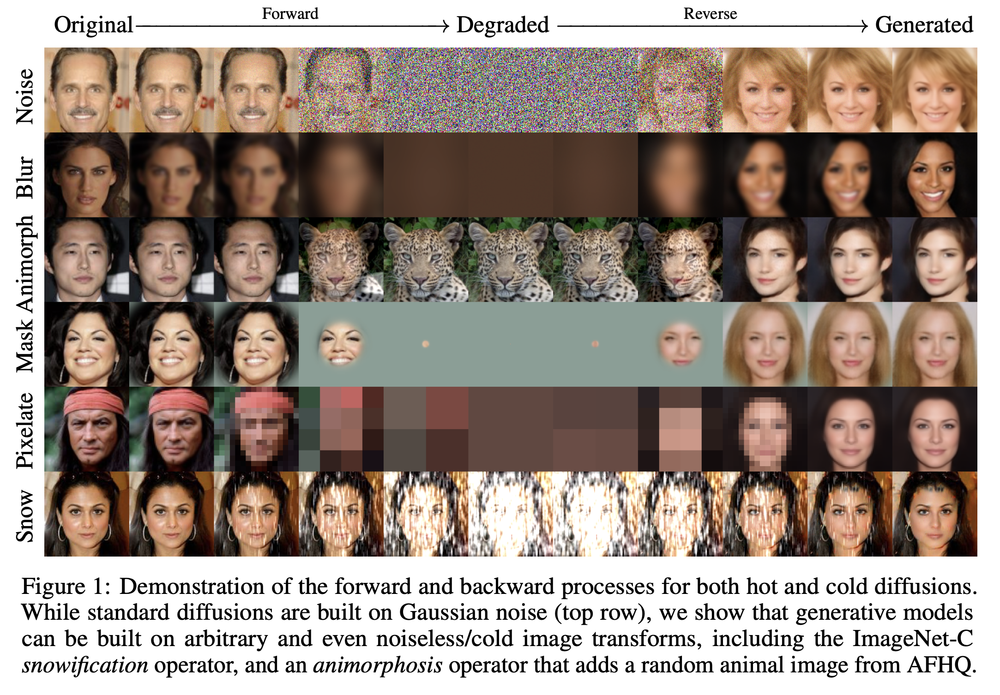


이는 노이즈 대신 다른 이미지 변환을 사용할 수 있음을 의미하낟. 예를 들어 Mise, MaskGIT, Paella와 같은 모델은 손상 방법으로 무작위 토큰 마스킹(random token masking)이나 대체(replacement)를 사용헀다. 그러나 다음과 같은 이유로 노이즈를 추가하는 방법을 가장 많이 사용한다. 
- 노이즈 양을 마음대로 조절할 수 있어서 완벽한 이미지에서 완전히 손상된 이미지까지 부드럽게 변화시킬 수 있다. 이는 이미지 해상도를 낮추는 것처럼 뚝뚝 끊어지는 변화가 아닌 연속적인 변화를 만들 수 있다는 장점이 있다. 
- 추론에서 다양한 무작위 상태를 시작점으로 사용할 수 있다. 반면 일부 손상 방식은 완전히 검은 이미지나 단일 픽셀만 있는 이미지처럼 가능한 초기 상태가 몇 가지로 제한될 수 있다. 


### 3.2 간단하게 시작하기

간단히 이미지 x에 무작위 노이즈를 추가하는 작업부터 시작해보자. 'torch.rand_like()' 함수를 사용하면 입력 이미지와 똑같은 크기의 순수한 가우시안 노이즈를 만들 수 있다. 

In [14]:
x = next(iter(train_dataloader))["images"][:8]
noise = torch.rand_like(x)

다양한 양의 잡읍음을 추가하는 한 가지 방법은 이미지외 노이즈 사이를 일정한 양으로 선형 보간(linear interpolation, lerp)하는 것이다. 이는 원본 이미지 \mathbf{x}에서 순수한 노이즈로 부드럽게 전환하는 함수를 제공한다. 

In [15]:
def corrupt(x, noise, amount):
   
    # amount를 원ㄴ본 데이터와 올바르게 작동하도록 재구성
    amount = amount.view(-1, 1, 1, 1,)

    # 양에 따라 원본 데이터와 노이즈를 혼합
    return(
        x * (1 - amount) + noise * amount
    )
    # x.lerp(noise, amount)와 동일함

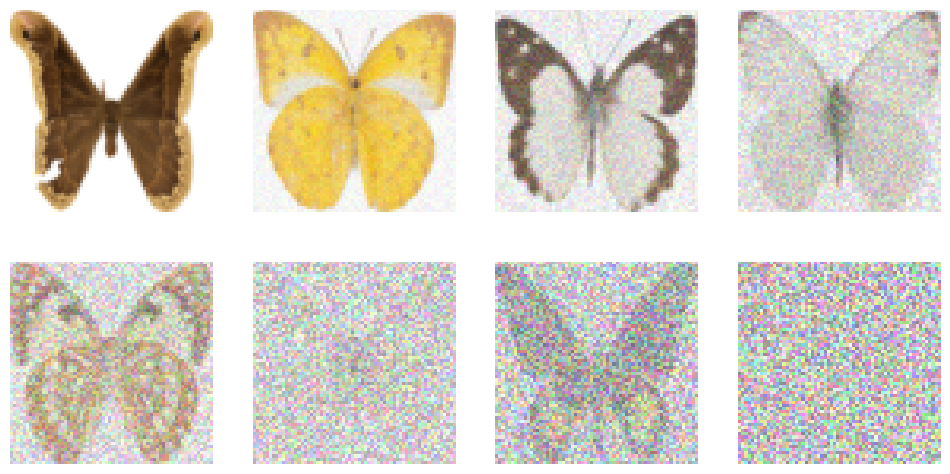

In [16]:
amount = torch.linspace(0, 1, 8)
noised_x = corrupt(x, noise, amount)
show_images(noised_x * 0.5 + 0.5)

원본 이미지에서 순수 노이즈로의 전환이 부드럽게 이루어진다. continuous time 접근 방식으로 노이즈 스케줄을 생성했으며, 이 방식에서는 전체 경로를 0에소 1까지의 시간 척도로 나타낸다. 다른 접근 방식들은 discrete time을 사용하는데, 노이즈 스케줄러를 정의하는데 큰 정수 타임 스텝들이 사용된다. 연속 시간을 이산 타임스텝으로 변환하고 적절하개 노이즈를 추가하는 클래스로 함수를 감쌀 수 있다. 

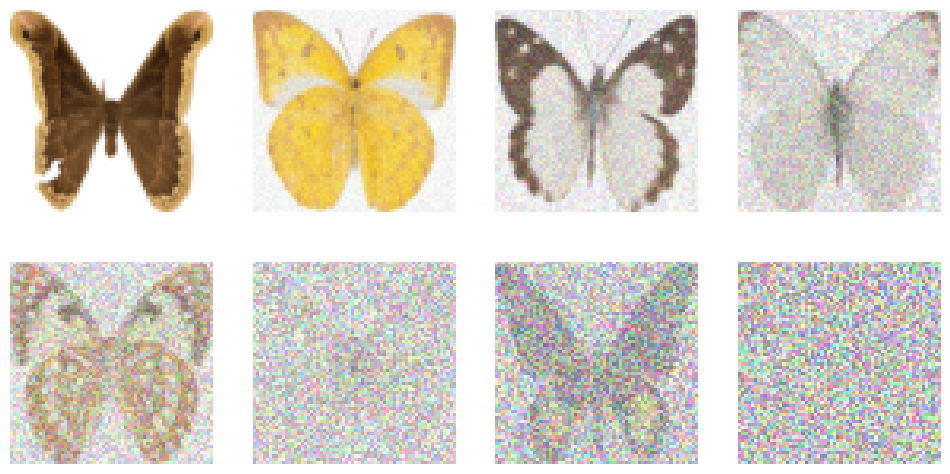

In [17]:
class SimpleScheduler:
    def __init__(self):
        self.num_train_timesteps = 1000
    

    def add_noise(self, x, noise, timesteps):
        amount = timesteps / self.num_train_timesteps
        return corrupt(x, noise, amount)

scheduler = SimpleScheduler()
timesteps = torch.linspace(0, 999, 8).long()
noised_x = scheduler.add_noise(x, noise, timesteps)
show_images(noised_x * 0.5 + 0.5)


이제 Diffuser 라이브러리에서 사용하는 스케줄러와 직접 비교할 수 있는 것이 생겼다. 예를 들어 학습중에 사용한 'DDPMScheduler'와 비교해보자. 

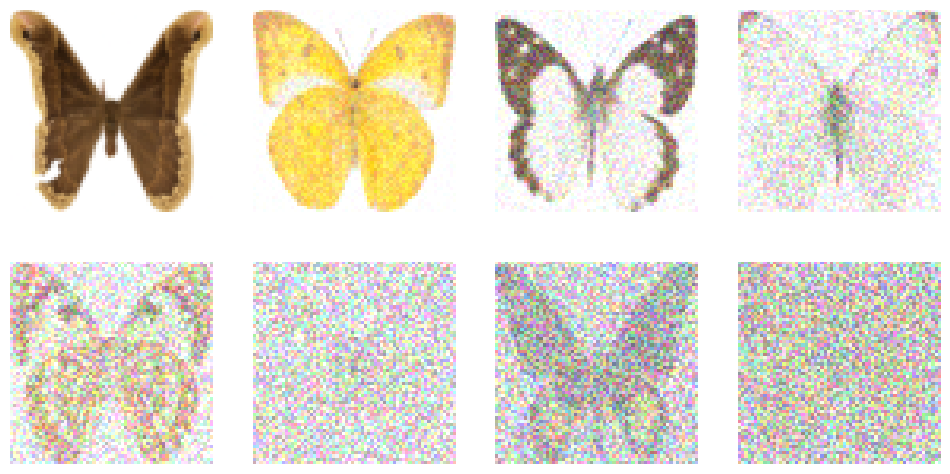

In [18]:
scheduler = DDPMScheduler(beta_end=0.01)
timesteps = torch.linspace(0, 999, 8).long()
noised_x = scheduler.add_noise(x, noise, timesteps)
show_images((noised_x * 0.5 + 0.5).clip(0, 1))

Diffuser 라이브러리의 DDPMScheduler와 직접 만든 스케줄러의 결과를 비교해보면 완전히 동일하지는 않지만 충분히 비슷함을 알 수 있다. 이 정도면 직접 만든 노이즈 스케줄러러도 모델 학습을 시도해 볼 수도 있다. 

### 3.3 수학적 배경

원본 이미지에 노이즈를 추가하는 방법의 수학적 배경을 자세히 살표보자. 문헌에는 많은 표기법과 접근 방식이 있다는 점을 기억하자. 예를 들어 일부 논문에서는 노이즈 스케줄이 연속해서 매개변수화되어 't'가 'corrupt'함수에서 했듯이 0(노이즈 없음)에서 1(완전히 손상됨)까지 실행된다. 다른 논문에서는 타임스텝이 정수이고 0에서 큰 수 'T'(일반적으로 1000)까지 실행되는 이산 시간 접근 방식을 사용한다. SimpleSchdeduler 클래스에서 했듯이 이 두 접근 방식이 서로 변환할수 있지만, 다른 모델을 비교할 때 일관성을 유지해야 한다. 여기서는 이산 시간 방식을 계속 사용할 것이다. 

이제 수학적인 부분에 대해서 살펴보자. (https://arxiv.org/pdf/2006.11239)

타임 스텝 t-1에서 타임스텝 t로 가는 단일 노이즈 단계부터 정의해보자. 앞서 설명했듯이 가우시안 노이즈(\epsilon)을 추가하는 것이 기본 아이디어다. 노이즈는 단위 분산을 가지며, 이는 노이즈 값의 분포를 제어한다. 이 노이즈를 이전 단계의 이미지에 추가해 원본 이미지를 점차 손상시키는데, 이는 확산 모델 학습 과정의 핵심이다. 

$$
\mathbb{x}_t = \mathbb{x}_{t-1} + \epsilon 
$$

각 단계에서 추가되는 노이즈 양을 조절하는 베타 t($\beta_t$)를 도입해보자. 이 매개변수는 모든 타임스텝 $t$에 대해 정의되며, 각 단계에서 얼마나 많으 논이즈가 추가되어야 하는지 결정한다. 다시 말해 $\mathbb{x}_t$는 $\mathbb{x}_{t-1}$ 과 $\beta_t$로 스케일링된 무작위 노이즈의 혼합이다. 이를 통해 타임스텝이 진행됨에 따라 이미지에 추가되는 노이즈 양이 점진적으로 증가시킬 수 있다. 

$$
\mathbb{x}_t = \sqrt{1-\beta_t} \mathbb{x}_{t-1} + \sqrt{\beta_t} \epsilon
$$

노이즈 추가 과정을 분포로 더 정의할 수 있는데, 여기서 노이즈가 추가된 $\mathbb{x}_t$는 평균 $\sqrt{1-\beta_t}\mathbb{x}_{t-1}$과 분산 \beta_t를 가진다. 이 분포는 노이즈 추가 과정을 더 정확하게 모델링하는데 도움이 된다. 분포 형태로 표현하면 다음과 같다. 

$$
q(\mathbb{x}_t \mid \mathbb{x}_{t-1}) = \mathcal{N}(\mathbb{x}_t; \sqrt{1-\beta_t} \mathbb{x}_{t-1}, \beta_t \mathbb{I})
$$

이제 이전 값을 조건으로 하는$x$를 샘플링하기 위한 분포를 정의했다. 타임스텝 $t$ 에서 노이즈가 추가된 입력을 얻으려면 $t = 0$에서 시작해 이 단일 단계를 반복 적용할 수 있지만, 매우 비효율적이다. 대신 재매개변수화 기법(reparameterization trick)을 사용해 한 번에 어떤 타임 스텝 $t$로도 이동할 수 있는 공식을 찾을 수 있다. 아이디어는 노이즈 스케줄을 미리 계산하는 것인데, 이는 $\beta_t$값으로 정의된다. 그런 다음 $\alpha_t = 1-\beta_t$외 $\bar{\alpha}$를 시간 $t$까지의 모든 $\alpha$값의 누적 곱으로 정의할 수 있으며, 이는 $\bar{\alpha}:=\Pi^t_{s=1}\alpha_s$로 표현된다. 이러한 도구와 표기법을 사용해 분포와 특정 시간에 샘플링하는 방법을 재정의할 수 있다. 새로운 분포 $q(\mathbb{x}_t \mid \mathbb{x}_{t-1})$로 표현된다. 이러한 도구와 표기법을 사용해 분포와 특정 시간에 샘플링하는 방법을 재정의할 수 있다. 

$$
q(\mathbb{x}_t \mid \mathbb{x}_{t-1}) = \mathcal{N}(\mathbb{x}_t; \bar{\alpha}_t \mathbb{x}_{t-1}, (1-\bar{\alpha}_t)\mathbb{I})
$$

이러한 reparameterization trick에 관한 자세한 탐구는 이 장의 마지막에 다음 공식을 이용하면 타임스텝 $t$ 지점에서 노이즈가 포함된 이미지를 얻을 수 있다. 

$$
\mathbb{x}_t = \sqrt{\bar{\alpha_t}}\space \mathbb{x}_0 + \sqrt{1-\bar{\alpha_t }} \space \epsilon

$$

$x_t$에 대한 이 방정식은 타임스텝 $t$에서의 노이즈가 추가된 입력이 원본 이미지 $x_0$($\sqrt{\bar{\alpha_t}}$로 스케일링 됨)와 $\epsilon$($\sqrt{1-\bar{\alpha_t}}$로 스케일링 됨)의 조합임을 보여준다. 이제 모든 이전 타임스텝을 반복하지 않고도 샘플을 직접 계산할 수 있어, 확산 모델을 훨씬 더 효울적으로 학습시킨다. 

Diffuser 라이브러리에서 $\bar{\alpha}$의 값은 'scheduler.alphas_cumprod'에 저장된다. 이를 ㅇ라면 주어진 스케줄러에 대해 다양한 타음스텝에서 원본 이미지 $x_0$와 노이즈 $\epsilon$에 대한 스케일링 요소를 그래프로 표시할 수 있다. Diffuser 라이브러리는 초깃값(beta_start), 최종값(beta_end), 값의 변화 방식('beta_schedule="linear"')을 정의하여 베타값을 제어하도록 해준다. 'DDPMScheduler'에 대한 다음 그래프는 입력 이미지(파란색 선)와 추가되는 노이즈(주황색 선)의 양을 보여준다. 예상대로 타임스텝이 많을수록 노이즈가 더 많이 스케일링 되는 모습을 볼 수 있다. 

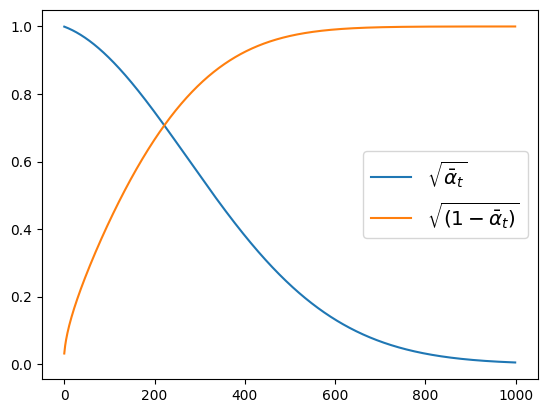

In [19]:
from genaibook.core import plot_scheduler

plot_scheduler(
    DDPMScheduler(beta_start=0.001, beta_end=0.02, beta_schedule="linear")
)

이 'SimpleScheduler'는 원본 이미지와 노이즈를 선형적으로 혼합한다. 이는 DDPM 경우의 $sqrt{\bar{\alpha_t}}$와 $1-sqrt{\bar{\alpha_t}}$에 해당하는 스케일링 요소를 그래프로 그리면 볼 수 있다. 

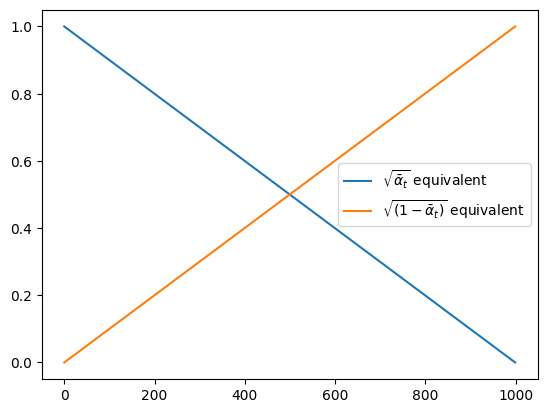

In [20]:
plot_scheduler(SimpleScheduler())

좋은 노이즈 스케줄은 모델이 다양한 노이즈 수준의 이미지를 골고루 보게 한다. 최선으 선택은 학습 데이터에 따라 달라진다. 몇 가지 추가 업션을 시각화하면 다음과 같은 특징을 알 수 있다. 
- 'beta_end'를 너무 낮게 설정하면 이미지가 완전히 손상되지 않아 모델이 추론의 시작점으로 사용하는 무작위 노이즈와 같은 것을 볼 기회가 없어진다. 
- 'beta_end'를 너무 높게 설정하면 대부분의 타임 스텝을 거의 완전한 노이즈 상태로 보내게 되어 학습 성능이 저하된다. 
- 다양한 베타 스케줄은 서로 다른 곡선을 제공한다. 코사인 스케줄은 원본 이미지에서 노이즈로 부드럽게 전환되어 인기가 있다. 

다음 그래프에서 하이퍼파라미터와 $\beta$ 스케줄울 변경하여 다양한 'DDPMScheduler' 스케줄러를 비교해보자. 

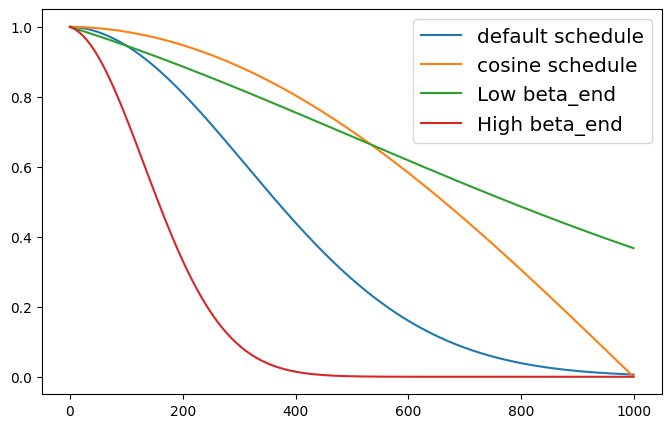

In [21]:
fig, (ax) = plt.subplots(1, 1, figsize=(8, 5))
plot_scheduler(
    DDPMScheduler(beta_schedule="linear"),
    label="default schedule",
    ax=ax,
    plot_both=False,
)

plot_scheduler(
    DDPMScheduler(beta_schedule="squaredcos_cap_v2"),
    label="cosine schedule",
    ax=ax,
    plot_both=False,
)

plot_scheduler(
    DDPMScheduler(beta_start=0.001, beta_end=0.003, beta_schedule="linear"),
    label="Low beta_end",
    ax=ax,
    plot_both=False,
)

plot_scheduler(
    DDPMScheduler(beta_start=0.001, beta_end=0.1, beta_schedule="linear"),
    label="High beta_end",
    ax=ax,
    plot_both=False,
)

- 여기서 보여주는 모든 스케줄은 variance preserving(VP)라고 부르며, 이는 모델 입력의 분산이 전체 스케줄에 걸쳐 $\mathbb{I}$에 가깝게 유지됨을 의미한다. 분산 폭발 (variance exploding, VE)공식도 있는데, 원본 이미지에 다양한 양의 노이즈가 추가되어 고분산 입력이 생성된다. 이 'SimpleScheduler'는 거의 분산 보존 스케줄이지만 선형 보간 때문에 분산이 완전히 보존되지는 않는다. 

https://arxiv.org/pdf/2305.08891 이 논문(Common Diffusion Noise Schedules and Sample Steps are Flawed)에서는 모델을 다양한 수준의 노이즈(초기 상태인 순수 노이즈 포함)가 있는 이미지에 노출하는 것의 중요성을 다루었다. 이 논문에서는 일부 호가산 모델이 학습 스케줄이 모든 상태를 포함하지 않아 너무 밝거나 어두운 이미지를 생성할 수 없음을 보여주었다. 

### 3,4 입력 해상도와 스케일링의 효과

최근까지 간과되었던 노이즈 스케줄의 한 측면은 입력 이미지 ㅋ기외 스ㅔ일링이 미치는 영향이다. 많은 연구자가 작은 데이터셋과 낮은 해상도에서 여러 스케줄러를 테스트한 다음, 성능이 가장 좋은 스케줄러를 골라 더 큰 이미지에서 최종 모델을 학습시킨다. 문제는 아래 그림처럼 크기가 다른 두 이미지에 같은 양의 노이즈를 추가할 때 발생한다. 

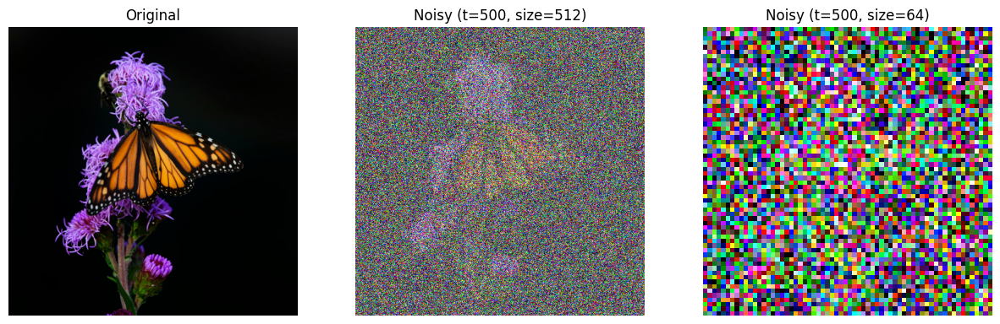

In [22]:

from genaibook.core import load_image

scheduler = DDPMScheduler(beta_end=0.05, beta_schedule="scaled_linear")
image = load_image(
    "https://images.pexels.com/photos/15403949/pexels-photo-15403949.jpeg",
    size=((512, 512)),
    return_tensor=True,
)
small_image = transforms.functional.resize(image, 64, antialias=True)
t = torch.tensor(500)  # The timestep we're noising to
show_images(
    [
        image,
        scheduler.add_noise(image * 2 - 1, torch.randn_like(image), t).clip(
            -1, 1
        )
        * 0.5
        + 0.5,
        scheduler.add_noise(
            small_image * 2 - 1, torch.randn_like(small_image), t
        ).clip(-1, 1)
        * 0.5
        + 0.5,
    ],
    titles=["Original", "Noisy (t=500, size=512)", "Noisy (t=500, size=64)"],
    figsize=(15, 5),
)

일반적으로 고해상도 이미지에는 많은 중복정보가 있다. 이는 일부 픽셀이 노이즈로 가려져도 주변 픽셀들에 원본 이미지를 복원할 충분한 정보가 있다는 뜻이다. 반면 저해상도 이미지에서는 각 픽셀에 중요한 정보가 있어서 같은 양의 노이즈를 추가하도라도 고해상도 이미지보다 훨씬 더 심하게 손상된다. 

2023년에 나온 두 개의 독립적인 논문이 이 현상을 자세히 다루었다. 두 논문 모두 새로운 통찰력을 바탕으로 기존의 복잡한 기법 없이도 고해상도 출력을 생성할 수 있는 모델을 학습시켰다. Simple Diffusion 논문(https://arxiv.org/pdf/2301.11093)에서는 입력 이미지 크기에 맞게 노이즈 스케줄을 조정하는 방ㅂ법을 제안했다. 이 덕분에 저해상도 이미지에 최적화된 스케줄을 새로운 목표 해상도에 맞게 적절히 수정할 수 있게 도었다. 다른 논문(https://arxiv.org/pdf/2301.10972)에서는 비슷한 실험을 수향하면서 또 다른 중요한 변수인 입력 스케일링에 주목했다. 즉, 이미지를 어떻게 표현할지가 중요한 사항이다. 이미지가 0과 1 사이의 부동 소수점으로 표햔된다면 보통 단위 분산을 가진 노이즈보다 낮은 분산을 갖게 된다. 따라서 특정 노이즈 수준에서의 신호 v.s. 노이즈 비율은 이미지가 -1과 1 사이(앞선 예제에서 사용한 방식)나 다른 방식으로 표현될 때보다 낮아진다. 입력 이미지의 스케일링을 조정하면 신호 대 노이지ㅇ 비율이 변하므로, 이 스케일링을 수정하는 것은 더 큰 이미지에 대한 학습을 조정하는 또 다른 효과적인 방법이다. 이 논문은 실제로 입력 스케일링이 다양한 이미지 크기에 대한 학습을 쉽게 조정하는 방법이라고 제안한다. 해상도에 따라 노이즈 스케줄을 직접 조정할 수도 있지만 여러 hyperparameter를 조정해야해서 최적의 스케줄을 찾기가 어려워진다. 다음은 입력 스케일링이 미치는 영향을 보여준다. 

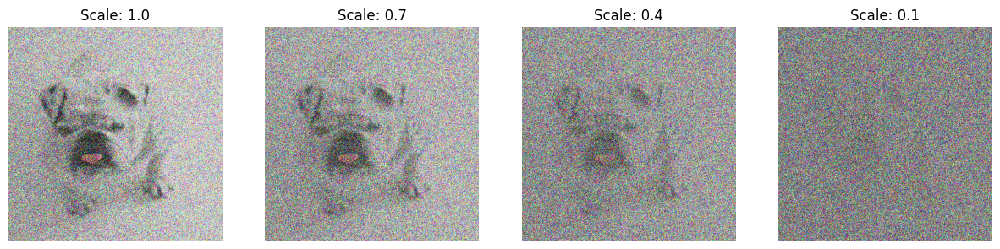

In [23]:
import numpy as np
from genaibook.core import load_image, SampleURL, show_images

scheduler = DDPMScheduler(beta_end=0.05, beta_schedule="scaled_linear")
image = load_image(
    SampleURL.DogExample,
    size=(512, 512),
    return_tensor=True,
)
t = torch.tensor(300)
scales = np.linspace(0.1, 1.0, 4)
images = [image]
noise = torch.randn_like(image)
for b in reversed(scales):
    noised = (
        scheduler.add_noise(b * (image * 2 - 1), noise, t).clip(-1, 1) * 0.5 + 0.5
    )
    images.append(noised)
show_images(
    images[1:],
    nrows=1,
    titles=[f"Scale: {b}" for b in reversed(scales)],
    figsize=(15, 5),
) 

모든 이미지 단계에는 단계 't=300'에 해당한는 동일한 입력 노이즈를 적용했지만 입력 이미지에 달느 스케일 요소를 곱했다. 스케일이 이미지에 더 많은 영향을 미치면 노이즈가 더 눈에 띈다. 스케일은 또한 동적 범위(또는 분산)을 감소시켜 입력이 더 어둡게 보인다. 이 방식에서는 모델에 전달되기 전에 입력 이미지가 정규화되어 분산이 급격히 감소하지 않도록 한다. 

## 4. U-Net과 대안 심층 분석

중요한 예측을 수행하는 실제 모델을 살펴보자. 요약하면 이 모델은 노이즈가 있는 이미지를 입력받아 그 노이즈를 출력할 수 있어여 하며, 이를 통해 입력 이미지를 디노이징할 수 잇다. 그러려면 임의 크기의 이미지를 입력받아 동일한 크기의 이미지를 출력하는 모델이 필요하다. 또한 모델은 이미지에 대한 고수준 정보를 포착하면서 픽셀 수준에서 정확한 예측을 해야한다. 인기있는 접근 방식은 U-Net이라는 아키텍쳐를 사용하는 것이다. 이는 2015년 의료 영상 분할용으로 발명되었으며 이후 다양한 이미지 관련 작업에 사용되었다. 

이전 장에서 살펴본 AE와 VAE처럼 U-Net은 downsampling 및 upsampling 블록 시리즈로 구성된다. downsampling block은 이미지 크기를 줄이고 upsampling block은 이미지 크기를 확대하는 역할을 한다. 
- downsampling block은 일반적으로 conv layer를 포함하고, 이어서 pooling이나 downsampling layer로 구성된다. 
- upsampling block은 일반적으로 일련의 conv layer를 포함하고, 이어서 upsampling이나 transposed conv layer를 포함한다. transposed conv layer는 이미지 크기를 확대하는 특별한 conv layer이다. 
  
일반 AE, VAE는 저차원 latent space에서 이미지를 재구성해야 하므로, 픽셀 수준에서 정확한 예측을 하는데 적합하지 않다. U-Net에서는 downsampling 및 upsampling 블록이 스킵 연결로 연결되는데, 이는 정보가 downsampling block에서 upsampling block으로 직접 흐르도록 한다. 이로써 모델은 이미지 전체에서 고수준 정보를 포착하면서도 픽셀 수준에서 정확한 예측을 할 수 있다. 

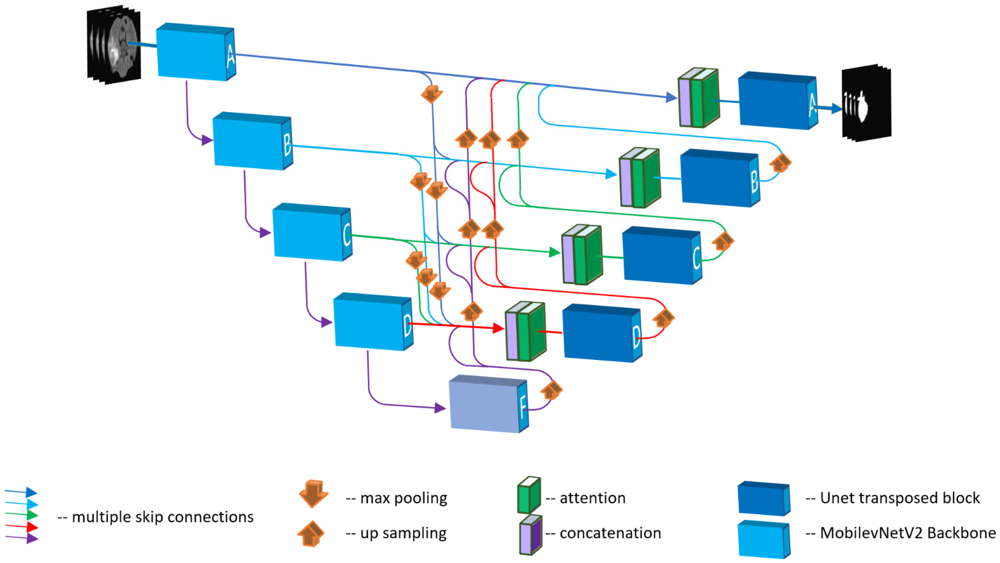

단일 채널 이미지(흑백)에서 작동하는 U-Net을 설계해보자. 이는 MNIST와 같은 데이터셋에 대한 확산 모델을 구축하는데 사용할 수 있다. downsampling 경로와 upsampling 경로에 각각 3개의 층을 사용할 것이다. 각 층은 encoding이나 decoding 걍로에 있는지에 따라 convolution 다음에 활성화 함수와 upsampling/downsampling 단계로 구성된다. 앞서 언급했듯이 스킵 연결은 downsampling 블록을 upsampling 블록에 직접 연결한다. 스킵 연결을 구현하는 방법은 여러가지가 있다.    

여기서는 downsampling block의 출력을 해당 upsampling block의 출력을 해당 upsampling block의 입력에 더하는 접근 방식을 사용한다. downsampling 블록의 출력을 upsampling 블록의 입력에 연결(concatenate)하는 방법도 있다. 스킵 연결에 일부 층을 추가할 수도 있다. 

우선 초기 접근 방식으로 구조를 간단하게 유지해보자. 

In [49]:
from torch import nn

class BasicUnet(nn.Module):
    def __init__(self, in_channels=1, out_channels=1):
        super().__init__()
        self.down_layers = nn.ModuleList(
            [
                nn.Conv2d(in_channels, 32, kernel_size=5, padding=2),
                nn.Conv2d(32, 64, kernel_size=5, padding=2),
                nn.Conv2d(64, 64, kernel_size=5, padding=2),
            ]
        )
        self.up_layers = nn.ModuleList(
            [
                nn.Conv2d(64, 64, kernel_size=5, padding=2),
                nn.Conv2d(64, 32, kernel_size=5, padding=2),
                nn.Conv2d(32, out_channels, kernel_size=5, padding=2),
            ]

        )

        # SiLU activation func.사용, 다양한 특성(부드러움, 비단 조성 등) 덕분에 잘 작동
        self.act = nn.SiLU()
        self.downscale = nn.MaxPool2d(2)
        self.upscale = nn.Upsample(scale_factor=2)

    def forward(self, x):
        h = []
        for i, l in enumerate(self.down_layers):
            x = self.act(l(x))

            # 세 번째(마지막) 하위 층을 제외한 모든 층
            if i < 2:
                h.append(x)           # 스킵 연결을 위한 출력 저장
                x = self.downscale(x) # 다음 층을 위한 다운 스케일
        for i, l in enumerate(self.up_layers):
            # 첫 번째를 제외한 모든 상위 층
            if i > 0:
                x = self.upscale(x) # 업스케일
                x += h.pop()        # 저장된 출력 가져오기(스킵 연결)
            x = self.act(l(x))

        return x


흑백 이미지 모양이 (1, 28, 28) 일 때, 모델을 거치는 경로는 다음과 같다. 
1. 이미지는 다운 스케일링 블록을 통과한다. 첫 번쨰 층은 2D 합성곱으로 32개의 필터를 사용하여 [32, 28, 28] 모델이 된다. 
2. 이미지는 최대 풀링으로 다운스케일링 되어 [32, 14, 14] 형태가 된다. MNIST 데이터셋에는 검은 배경에 흰 숫자가 그려져이ㅆ는데, 여기서 검은색은 숫자 0으로 표현된다. 최대 풀링을 선택해 특정 영역에서 가장 큰 값을 선택하고 가장 밝은 픽셀에 초점을 맞춘다. 
3. 이미지는 두 번째 스케일링된 블록을 통과한다. 두 번째 층은 64개의 필터가 있는 2D 합성곱을 사용해 [64, 14, 14] 형태가 된다. 
4. 다시 한번 다운 스케일링을 거쳐 [64, 7, 7] 형태가 된다. 
5. 다운 스케일링 블록에는 세 번째 층이 있지만, 이미 매우 작은 7x7 블록을 사용하므로 이번에는 다운 스케일링하지 않는다. 따라서 [64, 7, 7] 형태를 유지한다. 
6. 동일한 과정을 역순으로 수행하여 [64, 14, 14], [32, 14, 14], [1, 28, 28] 순으로 업스케일링한다. 

이 아키텍쳐로 학습된 확산 모델은 MNIST 데이터셋에서 다음과 같은 샘플을 만든다. 

In [50]:

from datasets import load_dataset

dataset = load_dataset("mnist")

In [51]:
import torch
from torch.utils.data import DataLoader
from torchvision import transforms

image_size = 32
batch_size = 8


def transform(examples):
    examples = [preprocess(image) for image in examples["image"]]
    return {"images": examples}


dataset.set_transform(transform)

# Define data augmentations
preprocess = transforms.Compose(
    [
        transforms.Resize((image_size, image_size)),  # Resize
        transforms.ToTensor(),  # Convert to tensor (0, 1)
    ]
)

train_dataloader = torch.utils.data.DataLoader(
    dataset["train"], batch_size=batch_size, shuffle=True
)
     

Input shape: torch.Size([8, 1, 32, 32])


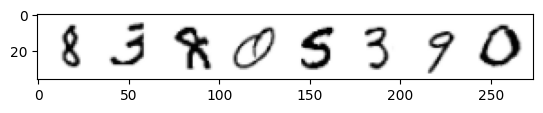

In [52]:

import torchvision
from matplotlib import pyplot as plt

imgs = next(iter(train_dataloader))["images"]
print("Input shape:", imgs.shape)
plt.imshow(torchvision.utils.make_grid(imgs)[0], cmap="Greys");

We make sure the images are the expected size, just as in the chapter. We also visualize a few images to get a sense of the data. Note we do not do random flips (it would not make much sense for digits!) and we use values between 0 and 1 for the pixel values.

#### Corruption
Let's implement a function that will add some amount of configurable noise to the input images. This is the same as in the chapter.

In [53]:

def corrupt(x, noise, amount):
    amount = amount.view(-1, 1, 1, 1)  # make sure it's broadcastable
    return (
        x * (1 - amount) + noise * amount
    )  # equivalent to x.lerp(noise, amount)

visualizing the efect of applying noise to the images.

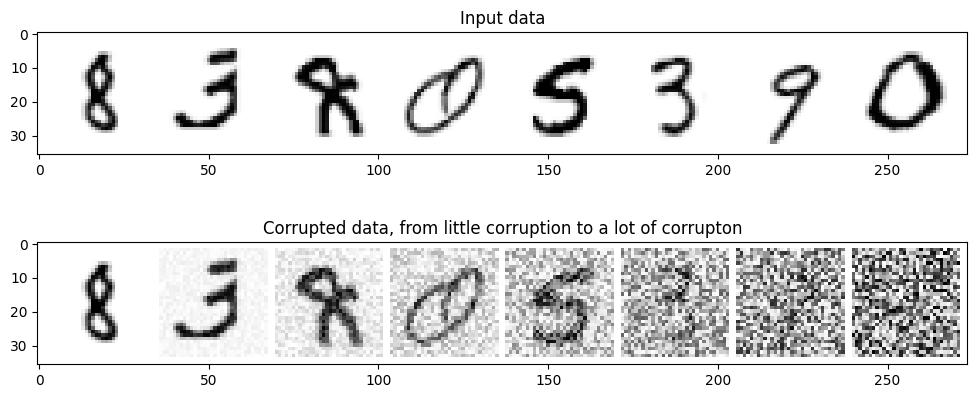

In [54]:
# Plotting the input data
fig, axs = plt.subplots(2, 1, figsize=(12, 5))
axs[0].set_title("Input data")
axs[0].imshow(torchvision.utils.make_grid(imgs)[0], cmap="Greys")

# Adding noise (we go from little corruption to a lot)
amount = torch.linspace(0, 1, imgs.shape[0])
noise = torch.rand_like(imgs)
noised_x = corrupt(imgs, noise, amount)

# Plotting the noised version
axs[1].set_title("Corrupted data, from little corruption to a lot of corrupton")
axs[1].imshow(torchvision.utils.make_grid(noised_x)[0], cmap="Greys")
     

#### Basic UNet
We begin by using a minimal UNet as described in the book (implementation at the top of this section). Some details about this UNet

- Works with single-chanel images, such as grayscale images.
- Has a downscaling and an upscaling path, each with three layers
- Each layer consists on a convolution and an activation (nn.SiLU) followed by a downscaling or upscaling step. Note that neither the last layer of the downscaling nor the first layer of the upscaling perform the down or upscaling.
- There are skip connections between downsampling and upsampling blocks.
Let's verify that the output shape is the same as the input:


In [55]:

net = BasicUnet()
x = torch.rand(8, 1, 32, 32)
net(x).shape

torch.Size([8, 1, 32, 32])

#### Training Model
Let's recall the process. For each training step, we:

Load a batch of images,
Add noise to the images,
Feed the noisy images into the model,
Calculate the loss.
Backpropagate and update weights with the optimizer.

In [56]:
from torch.nn import functional as F

device = get_device()
num_epochs = 5  # How many runs through the data should we do?
batch_size = 128

train_dataloader = torch.utils.data.DataLoader(
    dataset["train"], batch_size=batch_size, shuffle=True
)

model = BasicUnet().to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
losses = []  # Somewhere to store the loss values for later plotting

# Train the model
for epoch in range(num_epochs):
    for batch in train_dataloader:
        # Load the input images
        clean_images = batch["images"].to(device)

        # Sample noise to add to the images
        noise = torch.rand_like(clean_images).to(device)

        # Sample amount of noise to add to the images
        # In the chapter, we use the noise scheduler to manage this
        # as we can pass the timestep. Here, we keep it simple and
        # just sample a random amount of noise to add to the images.
        noise_amount = torch.randn(clean_images.shape[0]).to(device)

        # Add noise to the clean images according to the noise magnitude
        noisy_x = corrupt(clean_images, noise, noise_amount)

        # Get the model prediction
        pred = model(noisy_x)

        # Compare the prediction with the actual image
        # Big note: in the book, we optimize the model to reduce difference
        # the generation and the noise, so the model learns to predict the noise.
        # Here, we calculate the loss between the image and the generation, so the
        # model learns to generate the images directly.
        loss = F.mse_loss(pred, clean_images)

        # Update the model parameters with the optimizer based on this loss
        opt.zero_grad()
        loss.backward()
        opt.step()

        # Store the loss for later plotting
        losses.append(loss.item())

    # Print our the average of the loss values for this epoch:
    avg_loss = sum(losses[-len(train_dataloader) :]) / len(train_dataloader)
    print(
        f"Finished epoch {epoch}. Average loss for this epoch: {avg_loss:05f}"
    )

Finished epoch 0. Average loss for this epoch: 0.017511
Finished epoch 1. Average loss for this epoch: 0.010689
Finished epoch 2. Average loss for this epoch: 0.009700
Finished epoch 3. Average loss for this epoch: 0.009158
Finished epoch 4. Average loss for this epoch: 0.008997


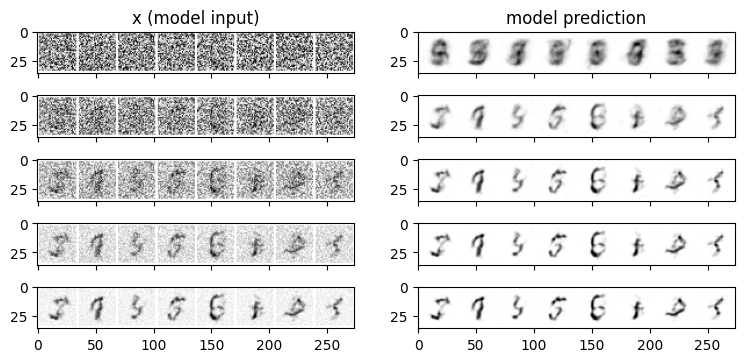

In [57]:

n_steps = 5
x = torch.rand(8, 1, 32, 32).to(device)  # Start from random
step_history = [x.detach().cpu()]
pred_output_history = []

for i in range(n_steps):
    # Predict denoise image
    with torch.no_grad():
        pred = model(x)

    # Store output for plotting
    pred_output_history.append(pred.detach().cpu())

    # Move slightly towards that direction
    mix_factor = 1 / (n_steps - i)
    x = x * (1 - mix_factor) + pred * mix_factor

    # Store output for plotting
    step_history.append(x.detach().cpu())

fig, axs = plt.subplots(n_steps, 2, figsize=(9, 4), sharex=True)
axs[0, 0].set_title("x (model input)")
axs[0, 1].set_title("model prediction")
for i in range(n_steps):
    axs[i, 0].imshow(
        torchvision.utils.make_grid(step_history[i])[0].clip(0, 1), cmap="Greys"
    )
    axs[i, 1].imshow(
        torchvision.utils.make_grid(pred_output_history[i])[0].clip(0, 1),
        cmap="Greys",
    )

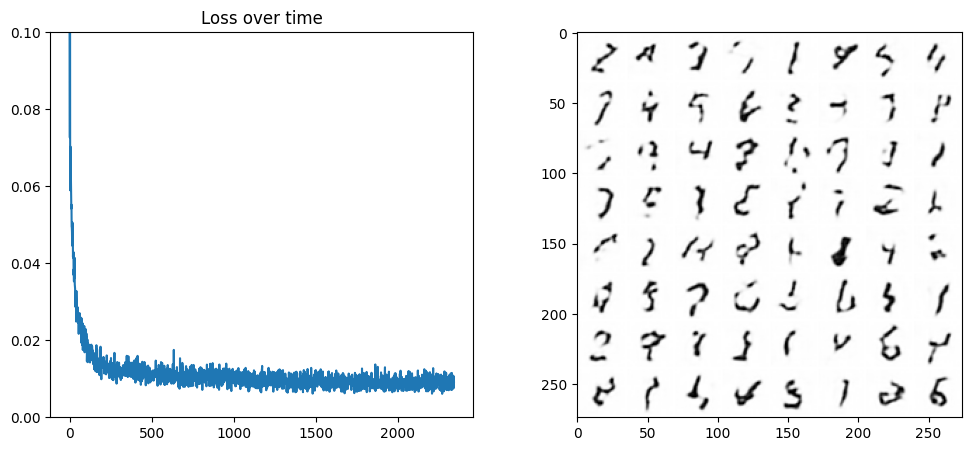

In [58]:

import torchvision
from matplotlib import pyplot as plt

# Plot losses and some samples
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# Losses
axs[0].plot(losses)
axs[0].set_ylim(0, 0.1)
axs[0].set_title("Loss over time")

# Samples
n_steps = 40
x = torch.rand(64, 1, 32, 32).to(device)
for i in range(n_steps):
    noise_amount = torch.ones((x.shape[0],)).to(device) * (
        1 - (i / n_steps)
    )  # Starting high going low
    with torch.no_grad():
        pred = model(x)
    mix_factor = 1 / (n_steps - i)
    x = x * (1 - mix_factor) + pred * mix_factor
axs[1].imshow(
    torchvision.utils.make_grid(x.detach().cpu(), nrow=8)[0].clip(0, 1),
    cmap="Greys",
)

In [59]:

basic_losses = losses
basic_model = model
     

#### Diffusers UNet
Let's now use the diffusers library UNet implementation. This integrates a couple of additions:

- More parameters (e.g. by having two convolutional layers per block)
- Batch normalization, which helps learn more quickly and reliably.
- Self-attention layers that allow to focus on different pars of the images at different times.

In [60]:
from diffusers import UNet2DModel

model = UNet2DModel(
    sample_size=32,
    in_channels=1,
    out_channels=1,
    layers_per_block=2,  # how many ResNet layers to use per UNet block
    block_out_channels=(32, 64, 64),  # Roughly matching our basic unet example
    down_block_types=(
        "DownBlock2D",
        "AttnDownBlock2D",
        "AttnDownBlock2D",
    ),
    up_block_types=(
        "AttnUpBlock2D",
        "AttnUpBlock2D",
        "UpBlock2D",
    ),
).to(device)

In [61]:
sum(
    [p.numel() for p in model.parameters()]
)  # 1.7M vs the ~309k parameters of the BasicUNet

1707009

As this model is larger, the training will take a bit longer.

In [62]:
batch_size = 128
train_dataloader = DataLoader(
    dataset["train"], batch_size=batch_size, shuffle=True
)
num_epochs = 5

train_dataloader = torch.utils.data.DataLoader(
    dataset["train"], batch_size=batch_size, shuffle=True
)

opt = torch.optim.Adam(model.parameters(), lr=1e-3)
losses = []  # Somewhere to store the loss values for later plotting

# Train the model
for epoch in range(num_epochs):
    for batch in train_dataloader:
        # Load the input images
        clean_images = batch["images"].to(device)

        # Sample noise to add to the images
        noise = torch.rand_like(clean_images).to(device)

        # Sample amount of noise to add to the images
        noise_amount = torch.randn(clean_images.shape[0]).to(device)

        # Add noise to the clean images according to the noise magnitude
        noisy_x = corrupt(clean_images, noise, noise_amount)

        # Get the model prediction using timestep 0
        pred = model(noisy_x, 0).sample

        # Compare the prediction with the actual image
        # Big note: in the book, we optimize the model to reduce difference
        # the generation and the noise, so the model learns to predict the noise.
        # Here, we calculate the loss between the image and the generation, so the
        # model learns to generate the images directly.
        loss = F.mse_loss(pred, clean_images)

        # Update the model parameters with the optimizer based on this loss
        opt.zero_grad()
        loss.backward()
        opt.step()

        # Store the loss for later plotting
        losses.append(loss.item())

    # Print our the average of the loss values for this epoch:
    avg_loss = sum(losses[-len(train_dataloader) :]) / len(train_dataloader)
    print(
        f"Finished epoch {epoch}. Average loss for this epoch: {avg_loss:05f}"
    )

Finished epoch 0. Average loss for this epoch: 0.012802
Finished epoch 1. Average loss for this epoch: 0.007438
Finished epoch 2. Average loss for this epoch: 0.006404
Finished epoch 3. Average loss for this epoch: 0.005846
Finished epoch 4. Average loss for this epoch: 0.005487


In [ ]:

# Plot losses and some samples
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# Losses
axs[0].plot(losses)
axs[0].set_ylim(0, 0.1)
axs[0].set_title("Loss over time")

# Samples
n_steps = 40
x = torch.rand(64, 1, 28, 28).to(device)
for i in range(n_steps):
    noise_amount = torch.ones((x.shape[0],)).to(device) * (
        1 - (i / n_steps)
    )  # Starting high going low
    with torch.no_grad():
        pred = model(x, 0).sample
    mix_factor = 1 / (n_steps - i)
    x = x * (1 - mix_factor) + pred * mix_factor

axs[1].imshow(
    torchvision.utils.make_grid(x.detach().cpu(), nrow=8)[0].clip(0, 1),
    cmap="Greys",
)
axs[1].set_title("Generated Samples");

Much better! Still, not perfect, but a great improvement for a model we can quickly train.

Plot losses together with the ones from the previous model.

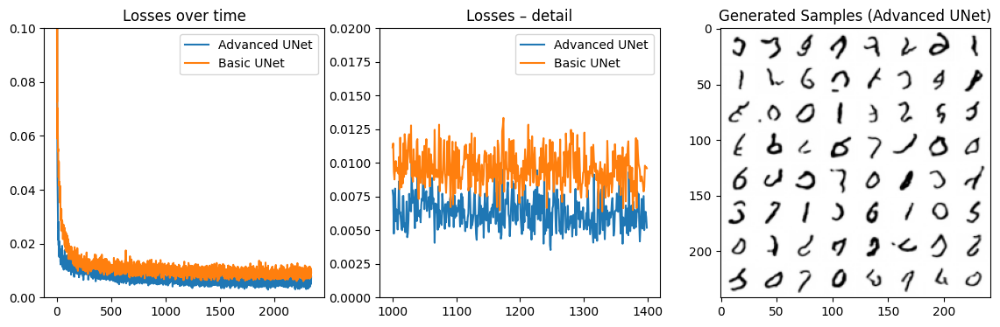

In [63]:
# Plot losses and some samples
fig, axs = plt.subplots(1, 3, figsize=(14, 4))
import numpy as np

# Losses
axs[0].plot(losses, label="Advanced UNet")
axs[0].plot(basic_losses, label="Basic UNet")
axs[0].set_ylim(0, 0.1)
axs[0].set_title("Losses over time")
axs[0].legend()

# Losses
axs[1].plot(losses[1000:1400], label="Advanced UNet")
axs[1].plot(basic_losses[1000:1400], label="Basic UNet")
axs[1].set_ylim(0, 0.02)
axs[1].set_title("Losses – detail")
axs[1].set_xticks(np.arange(0, 401, step=100), np.arange(1000, 1401, step=100))
axs[1].legend()

# Samples
n_steps = 40
x = torch.rand(64, 1, 28, 28).to(device)
for i in range(n_steps):
    noise_amount = torch.ones((x.shape[0],)).to(device) * (
        1 - (i / n_steps)
    )  # Starting high going low
    with torch.no_grad():
        pred = model(x, 0).sample
    mix_factor = 1 / (n_steps - i)
    x = x * (1 - mix_factor) + pred * mix_factor

axs[2].imshow(
    torchvision.utils.make_grid(x.detach().cpu(), nrow=8)[0].clip(0, 1),
    cmap="Greys",
)
axs[2].set_title("Generated Samples (Advanced UNet)");

#### In Depth: Diffusion Objectives

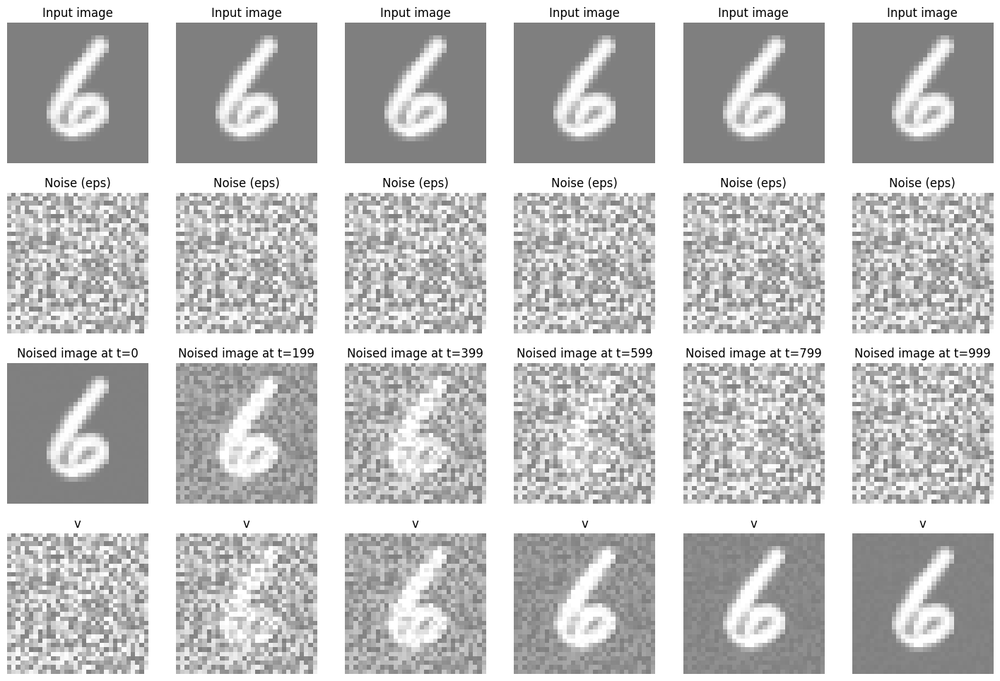

In [64]:
# Updated for large image sizes
scheduler = DDPMScheduler(beta_end=0.012)
sample = batch["images"][0]
image_size = sample.shape[-1]
noise_size = image_size  # 32
res_transform = transforms.Resize(noise_size, antialias=True)
x = res_transform(sample.expand(6, 3, image_size, image_size))
noise = torch.rand_like(res_transform(sample)).expand(
    6, 3, noise_size, noise_size
)
timesteps = torch.linspace(0, 999, 6).long()
noised_x = scheduler.add_noise(x, noise, timesteps)
alpha_bars = scheduler.alphas_cumprod[timesteps]
v = (
    alpha_bars.view(-1, 1, 1, 1).sqrt() * noise
    + (1 - alpha_bars.view(-1, 1, 1, 1)).sqrt() * x
)
images = torch.cat(
    [
        x,
        noise,
        noised_x,
        v,
    ],
    dim=0,
)
titles = (
    ["Input image"] * 6
    + ["Noise (eps)"] * 6
    + [f"Noised image at t={t}" for t in timesteps]
    + ["v"] * 6
)

show_images(images.clip(-1, 1) * 0.5 + 0.5, ncols=6, titles=titles)

### 4.2 U-Net 개선하기

이 간단한 U-Net은 비교적 쉬운 작업에 적합하다. 복잡한 데이터를 다루려면 다음과 같은 방법을 사용할 수 있다. 

#### 매개변수 추가
각 블록에서 여러 개의 합성곱 층을 사용하거나, 각 합성곱 층에 더 많은 필터를 사용하거나, 신경망을 더 깊게 만드는 방식으로 처리할 수 있다. 
#### 배치 정규화 같은 정규화 추가
배치 정규화는 각 층의 출력이 0을 중심우로 하고 표준편차가 1이 되도록 하여 모델이 빠르고 안정적으로 학습하도록 돕는다. 
#### 드롭아웃 같은 규제 추가
드롭 아웃은 작은 데아터셋을 다룰 때 중요한 문제인 과적합을 방지하는데 도움이 된다 
#### 어텐션 추가
self-attention layer을 도입하면 모델이 다른 시간에 이미지의 다른 부분에 잡중할 수 있어 U-Net이 더 복잡한 기능을 학습하는데 도움이 된다. transformer 유사 attention layer(transformer-like attention layer)을 추가하면 학습 가능한 매개변수 수도 늘릴 수 있다. 어텐션 층은 높은 해상도에서 계산하는데 일반 합성곱 층보다 비용이 훨씬 더 많이 든다는 단점이 있어 일반적으로 U-Net의 더 낮은 해상도 블록에서만 사용한다. 

아래의 그림은 여러 개선 사항을 포함한 diffuser library의 U-Net 구현을 사용했을 때 MNIST 에서의 결과를 기본 아키텍쳐와 비교해서 보여준다. 

(시간에 따른 손실, 손실-세부사하으 생성된 샘풀)
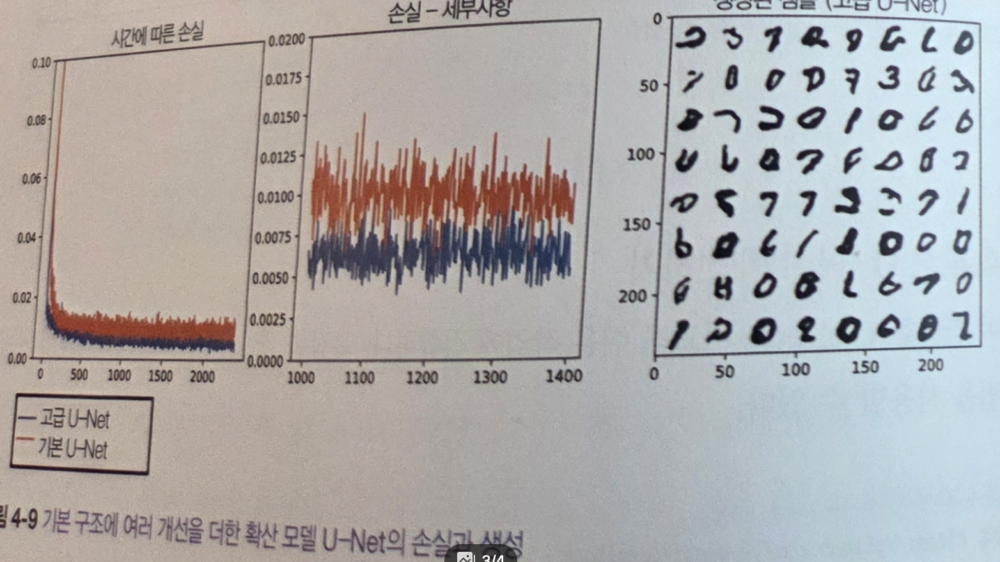

### 4.3 대안 아키텍쳐

최근에 확산 모델을 위해 여러 새로운 아키텍쳐가 제안되엇다. 이러한 아키텍쳐는 다음을 포함한다. 

#### Transformer
확산 트랜스포머 논문(https://arxiv.org/pdf/2212.09748)은 트랜스포머 기반 아키텍처가 우수한 결과로 확산 모델을 학습시킬 수 있음을 보여주었다. 그러나 매우 높은 해상도에서는 트랜스포머 아키텍처의 계산 및 메모리 요구사항이 여전히 도전 과제로 남아있다. 

#### UViT
단순 확산 논문(https://arxiv.org/pdf/2301.11093)의 UViT 아키텍쳐는 U-Net의 중간 층을 대규모 트랜스포머 블록 스택으로 대체해 두 가지의 장점을 모두 얻는 것을 목표로 한다. 이 논문의 핵심은 U-Net의 저해상도 블록에 대부분의 계산을 집중시키면 고해상도 확산 모델을 더 효율적으로 학습시킬 수 있다는 것이다. 매우 높은 해상도에는 wavelet transform을 사용한다. 이는 채널을 추가해 가능한 한 많은 정보를 유지하면서 입력 임지의 공간 해상도를 줄일 수 있는 추가 전처리를 수행한다. 이로써 더 높은 공간 해성도에 소비되는 계산량을 다시 줄일 수 있다. 

#### RIN(Recurrent Interface Network)
순환 인터페이스 네트워크(RIN, https://arxiv.org/pdf/2212.11972) 논문은 머넞 고해상도 입력을 더 관리하기 쉽고 저차원 latent representation으로 매칭한 다음, 트랜스포머 블록 스택으로 처리한 후 다시 이미지로 디코딩한다. 또한 recurence 이라는 개념을 도입해 이전 처리 단계의 정보를 모델로 전달하는 방식을 제안했다. 이는 확산 모델이 수행하도록 설계된 반복 개선에 도움이 될 수 있다. 

고품질 확산 모델에는 flux, stable diffusuin3, PixArt - $\Sigma$, text-to-video Sora가 포함된다. 트랜스포머 기반 접근 방식이 확산 모델의 주요 구조로 U-Net을 완전히 대체할지, UViT와 RIN 같은 하이브리드 접근 방식이 가장 효과적일지 지켜봐야 한다. 

## 4.5 확산 목표 심층 분석

확산 모델이 노이즈가 있는 입력을 받아 이를 디노이징하는 방법을 살펴보았다. 가볍게 보면 신경망의 자연스러운 예측 대상이 이미지의 디노이징된 버전인 x0이라고 가정할 수 있다. 그러나 코드에서 모델 예측을 노이즈가 있는 버전을 만드는데 사용된 단위 분산 노이즈($\epsilon$ 목표 함수나 'eps'라고도 함)와 비교했다. 노이즈와 타임스텝을 알면 x0을 도출할 수 있고, 그 반대도 가능하므로 두 가지는 수학적으로 동이랳 보인다. 이는 사실이지만, 목표 함수 선택은 서로 다른 타임스텝에서 손실의 크기에 따라서 모델이 디 노이징하는데 가장 잘 학습하는 노이즈 수준에 미묘한 영향을 미친다. 노이즈를 예측하는 것이 대상 데이터를 집접 예측하는 것보다 모델에게 더 쉽다. 이는 노이즈가 각 단계에서 알려진 분포를 따르며 두 단계 간의 차이를 예측하는 것이 대상 데이터의 절댓값을 예측하는 것보다 더 간단할 때가 많기 때문이다. 

다양한 타임스텝에 걸친 여러 목표 함수를 시각회해 더 명확히 이해해보자. 아래의 입력 이미지와 무작위 노이즈는 타임 스텝에 따라 일정하지만(그림의 처음 두 행), 노이즈가 추가된 이미지(세 번째 행)는 타임 스텝에 따라 다른 양의 노이즈가 추가된다. 
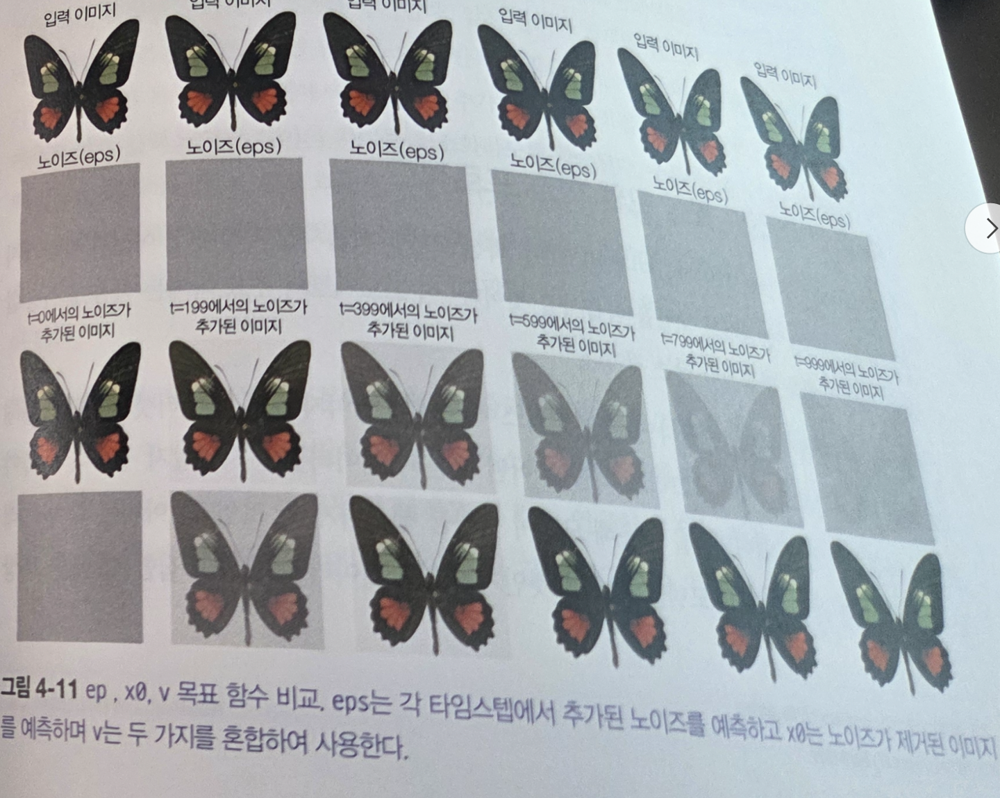

극도로 낮은 노이즈 수준에서는 x0 목표가 아주 쉽게 달성된다. 노이즈가 추가된 이미지가 입력 이미지와 거의 같기 때문이다. 하지만 노이즈를 정확하게 예측하는 일은 거의 불가능하다. 마판가지로, 극도로 높은 노이즈 수준에서 eps 목표 함수는 간단하다. (노이즈가 추가된 이미지가 거의 추가된 순수 노이즈와 동일함). 하지만 디노이징된 이미지를 정확하게 예측하는 일은 거의 불가능하다. x0 목표 함수를 사용하면 학습에서 낮은 노이즈 수준에 적은 가중치를 두게 된다. 

두 상황 모두 이상적이지 않으므로 다양한 타임스템 x0와 eps의 혼합을 예측하도록 모델에 지시하는 추가 목표 함수가 도입되었다. 앞선 그림의 마지ㅣ막 행에 보이는 속도(v) 목표 함수는 그러한 목표 함수 중 하나로, $\upsilon= \sqrt{\bar{\alpha}} \cdot \epsilon + \sqrt{1 - \bar{\alpha}} \cdot \mathbb{x}_0$로 정의된다. eps 목표 함수는 매우 선호되는 접근방식이지만 단점이 남아 있으며 다른 목표 함수도 있다는 점을 알아두어야 한다. 

### 4.6 비조건부 확산 모델 학습 프로젝트

이론은 충분히 살펴보았으니, 이제 비조건부 확산 모델을 학습시킬 차례이다. 이전과 마찬가지로 새 이미지를 생성하는 모델을 학습시킬 것이다. 이 프로젝트의 주요 과제는 학습에 사용할 좋은 데이터셋을 만들거나 찾는 것이다. 

기존 데이터셋을 사용하고 싶다면 허깅 페이스 허브에서 이미지 분류 데이터셋을 필터링해보는 것부터 시작하면 좋다. 그리고 학습에 어떤 부분의 데이터셋을 사용할지 생각해 보아야 한다. 이전처럼 전체 데이터셋을 사용해 모델이 숫자를 생성하게 할 것인가? 아니면 특정 클래 스(O cats)를 사용해 전용 모델을 생성할 것인가? 또는 데이터셋의 하위 집합(예 특정 해상도의 이미지만)을 사용할 것인가?

새 데이터셋을 올리고 싶다면 먼저 데이터를 찾고 접근해야 한다. 데이터셋을 공유하는 가장 간단한 접근 방식은 datasets 라이브러리의 ImageFolder 기능을 사용하는 것이다. 그런 다음 데이터셋을 허깅 페이스 허브에 올리고 프로젝트에서 사용할 수 있다. 

데이터를 확보한 후에는 전처리 단계, 모델 정의, 학습 루프에 관해 생각해 보자 이 강의 코드를 시작점으로 활용하고 데이터셋에 맞게 수정할 수 있다. 